##  Deep Learning PR 5
## Sentiment Analysis with RNN, LSTM and GRU

### Task 1: Text Loading, Cleaning, Tokenisation & Padding

**Objective:**  
Load the IMDB movie review dataset, clean the raw text, remove duplicate
reviews, analyse review lengths, split the dataset, tokenize the text and
convert reviews into padded integer sequences.

**Expected Output:**  
Cleaned and tokenized IMDB reviews converted into fixed-length padded
sequences ready for training ANN, SimpleRNN, LSTM and GRU models.

## Import Libraries

In [1]:
import os
import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Create folder required by later tasks
os.makedirs("plots", exist_ok=True)

print("TensorFlow Version:", tf.__version__)
print("Setup completed successfully.")

TensorFlow Version: 2.16.1
Setup completed successfully.


## Load Dataset

In [2]:
df = pd.read_csv("IMDB Dataset.csv")

print("Dataset loaded successfully.")
print("Dataset Shape:", df.shape)

Dataset loaded successfully.
Dataset Shape: (50000, 2)


## Inspect Dataset

In [3]:
print("First 5 rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

First 5 rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Dataset Shape:
(50000, 2)

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Missing Values:
review       0
sentiment    0
dtype: int64


## Print Two Raw Reviews

In [4]:
print("=" * 100)
print("RAW REVIEW 1")
print("=" * 100)
print(df["review"].iloc[0])

print("\n")

print("=" * 100)
print("RAW REVIEW 2")
print("=" * 100)
print(df["review"].iloc[1])

RAW REVIEW 1
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is d

# Task 1.2 — Remove Duplicates

## Check and Remove Duplicates

In [5]:
rows_before = len(df)

duplicate_count = df.duplicated().sum()

print("Rows before removing duplicates:", rows_before)
print("Duplicate rows:", duplicate_count)

df.drop_duplicates(inplace=True)

df.reset_index(drop=True, inplace=True)

rows_after = len(df)

print("Rows after removing duplicates:", rows_after)
print("Rows removed:", rows_before - rows_after)

Rows before removing duplicates: 50000
Duplicate rows: 418
Rows after removing duplicates: 49582
Rows removed: 418


### Why must duplicates be removed before the train/test split?

Duplicate reviews must be removed before splitting the dataset because
otherwise the same review could appear in both the training and test sets.

If the model has already seen a review during training and the identical
review appears in the test set, the test accuracy may become artificially
high.

This is a form of **data leakage** because information from the test data
has effectively been seen during training.

Therefore, duplicate reviews are removed before creating the train and
test sets.

# Task 1.3 — Clean Text

## Save Raw Review for Comparison

In [6]:
raw_example = df["review"].iloc[0]

print("Original Review:")
print(raw_example)

Original Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

## Create clean_text() Function

In [7]:
def clean_text(s):
    # Convert to string
    s = str(s)

    # Lowercase
    s = s.lower()

    # Remove HTML tags
    s = re.sub(r"<.*?>", " ", s)

    # Keep only letters and apostrophes
    s = re.sub(r"[^a-z']", " ", s)

    # Collapse repeated spaces
    s = re.sub(r"\s+", " ", s)

    # Remove leading/trailing spaces
    s = s.strip()

    return s

## Apply Cleaning

In [8]:
df["clean_review"] = df["review"].apply(clean_text)

print("Text cleaning completed.")

Text cleaning completed.


## Before vs After Cleaning

In [9]:
print("=" * 100)
print("BEFORE CLEANING")
print("=" * 100)
print(raw_example)

print("\n")

print("=" * 100)
print("AFTER CLEANING")
print("=" * 100)
print(df["clean_review"].iloc[0])

BEFORE CLEANING
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show i

### Why are apostrophes preserved?

Apostrophes are important because they preserve contractions such as:

- don't
- isn't
- wasn't
- can't

Removing the apostrophe can change the representation of these words and
may lose useful information related to negation.

### Why are stop words NOT removed?

Stop words are not removed because sequence models depend on both the
words and their order.

Words such as **not**, **no**, **never**, and similar terms can completely
change the sentiment of a sentence.

For example:

- "The movie was good."
- "The movie was not good."

Removing the word **not** would make these sentences appear much more
similar even though their sentiment is different.

Therefore, stop words are retained for this sequence-classification task.

# Task 1.4 — Review Length Analysis
## Calculate Review Length

In [10]:
df["review_length"] = df["clean_review"].apply(
    lambda text: len(text.split())
)

mean_length = df["review_length"].mean()
median_length = df["review_length"].median()
p90_length = df["review_length"].quantile(0.90)
p95_length = df["review_length"].quantile(0.95)

print(f"Mean Review Length       : {mean_length:.2f}")
print(f"Median Review Length     : {median_length:.2f}")
print(f"90th Percentile Length   : {p90_length:.2f}")
print(f"95th Percentile Length   : {p95_length:.2f}")
print(f"Maximum Review Length    : {df['review_length'].max()}")

Mean Review Length       : 229.96
Median Review Length     : 172.00
90th Percentile Length   : 449.00
95th Percentile Length   : 587.00
Maximum Review Length    : 2462


## Review-Length Histogram

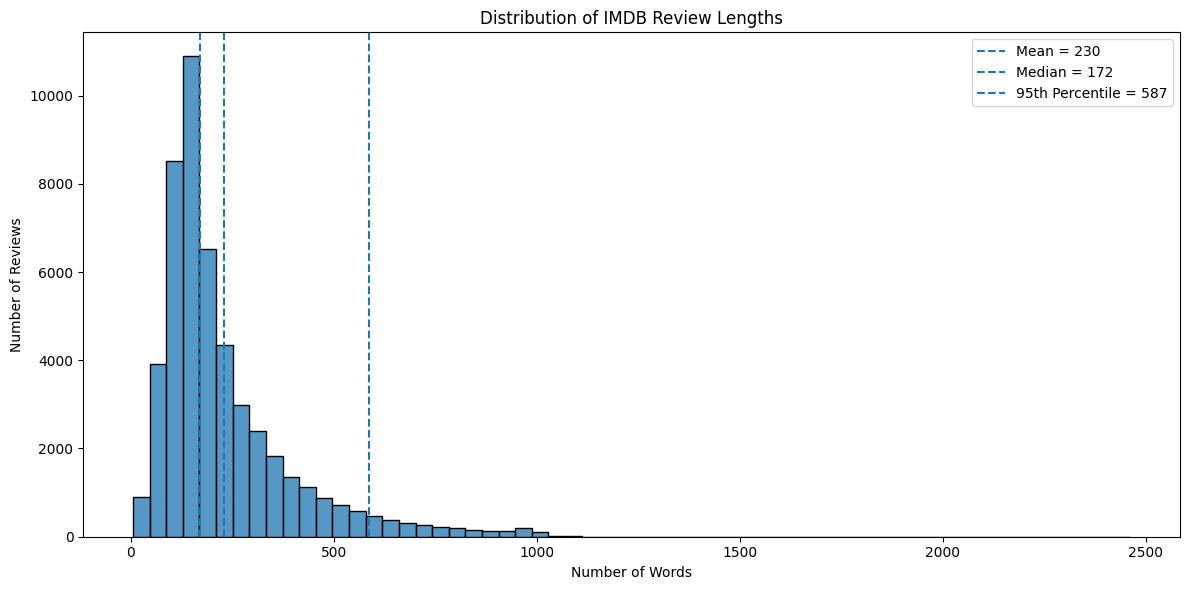

In [11]:
plt.figure(figsize=(12, 6))

sns.histplot(
    df["review_length"],
    bins=60
)

plt.axvline(
    mean_length,
    linestyle="--",
    label=f"Mean = {mean_length:.0f}"
)

plt.axvline(
    median_length,
    linestyle="--",
    label=f"Median = {median_length:.0f}"
)

plt.axvline(
    p95_length,
    linestyle="--",
    label=f"95th Percentile = {p95_length:.0f}"
)

plt.title("Distribution of IMDB Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.legend()

plt.tight_layout()

plt.savefig(
    "plots/length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Boxplot by Sentiment

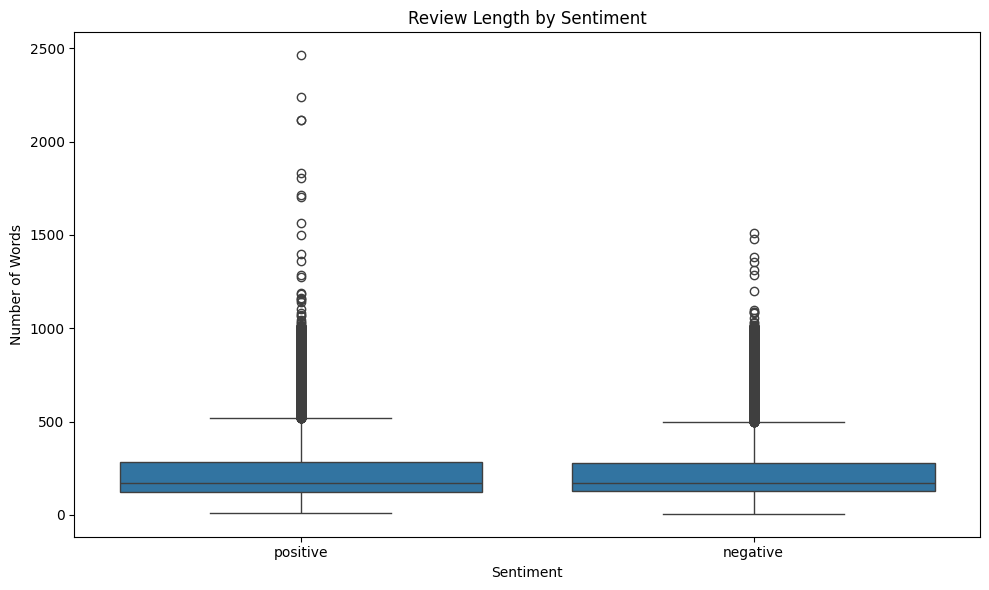

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="sentiment",
    y="review_length"
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.show()

## Choose MAXLEN

In [13]:
MAXLEN = int(np.ceil(p95_length / 50) * 50)

print("95th Percentile:", p95_length)
print("Selected MAXLEN:", MAXLEN)

95th Percentile: 587.0
Selected MAXLEN: 600


### Review Length Analysis

The review-length distribution is right-skewed. Most movie reviews are
relatively short or medium length, while a smaller number of reviews are
very long.

The mean is higher than the median because long reviews pull the average
towards the right.

I selected `MAXLEN` based approximately on the 95th percentile of the
review-length distribution and rounded it to a convenient value.

This retains most of the review content while preventing a relatively
small number of extremely long reviews from making every input sequence
unnecessarily large.

# Task 1.5 / 1.6 — Encode Target and Split
## Encode Sentiment

In [14]:
df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(df[["sentiment", "label"]].head())

print("\nLabel Distribution:")
print(df["label"].value_counts())

  sentiment  label
0  positive      1
1  positive      1
2  positive      1
3  negative      0
4  positive      1

Label Distribution:
label
1    24884
0    24698
Name: count, dtype: int64


## Prepare X and y

In [15]:
X_text = df["clean_review"]
y = df["label"].values

print("Number of Reviews:", len(X_text))
print("Target Shape:", y.shape)

Number of Reviews: 49582
Target Shape: (49582,)


## Train/Test Split

In [16]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Reviews:", len(X_train_text))
print("Testing Reviews :", len(X_test_text))

print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

Training Reviews: 39665
Testing Reviews : 9917
y_train shape: (39665,)
y_test shape : (9917,)


# Task 1.5 — Tokenisation
## Create and Fit Tokenizer

In [17]:
VOCAB_SIZE = 10000

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

# IMPORTANT:
# Fit ONLY on training reviews
tokenizer.fit_on_texts(X_train_text)

print("Tokenizer fitted on TRAINING data only.")
print("Total words discovered:", len(tokenizer.word_index))

Tokenizer fitted on TRAINING data only.
Total words discovered: 108132


## Top 10 Frequent Words

In [18]:
sorted_words = sorted(
    tokenizer.word_counts.items(),
    key=lambda x: x[1],
    reverse=True
)

print("Top 10 Most Frequent Words:\n")

for word, count in sorted_words[:10]:
    print(f"{word:<15} {count}")

Top 10 Most Frequent Words:

the             529753
and             258038
a               256817
of              230096
to              212541
is              167548
in              148539
it              124849
i               122942
this            119750


## Convert Text to Integer Sequences

In [19]:
train_sequences = tokenizer.texts_to_sequences(X_train_text)
test_sequences = tokenizer.texts_to_sequences(X_test_text)

print("First Training Review:")
print(X_train_text.iloc[0])

print("\nInteger Sequence:")
print(train_sequences[0])

First Training Review:
i am one of jehovah's witnesses and i also work in an acute care medical facility over the years i have seen people die from hemolytic reactions to blood transfusions have attended numerous conferences on blood born pathogens and have seen several patients become seriously ill from pathogens induced by transfused blood i have also heard several jehovah's witnesses being told that they will die if they refuse blood and after years in the field i have never actually seen it happen leaving the question is it really unreasonable to refuse blood transfusions or is the community at large benefiting from the battle on this issue the issue for jehovah's witnesses is a moral one you must abstain from blood is not an ambiguous statement thank you for this movie and allowing comments on it

Integer Sequence:
[10, 234, 27, 5, 1, 4935, 3, 10, 81, 158, 8, 32, 1, 454, 2767, 7929, 121, 2, 151, 10, 25, 105, 83, 705, 35, 1, 3781, 6, 547, 1, 25, 6453, 1909, 1, 20, 547, 1417, 1, 3, 

### Why use `num_words=10000`?

The vocabulary is limited to the 10,000 most frequent words because very
rare words increase the size and complexity of the model while often
contributing little useful information.

Limiting the vocabulary reduces noise, memory usage and the number of
parameters required by the embedding layer.

### What does the OOV token do?

`<OOV>` means **Out Of Vocabulary**.

When the model encounters a word that is not included in the selected
vocabulary, that word is represented using the OOV token instead of being
silently discarded.

This gives unknown and rare words a consistent representation.

# Task 1.6 — Padding
## Pad Sequences

In [20]:
X_train = pad_sequences(
    train_sequences,
    maxlen=MAXLEN,
    padding="pre",
    truncating="pre"
)

X_test = pad_sequences(
    test_sequences,
    maxlen=MAXLEN,
    padding="pre",
    truncating="pre"
)

print("Final Shapes")
print("-" * 40)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

Final Shapes
----------------------------------------
X_train: (39665, 600)
y_train: (39665,)
X_test : (9917, 600)
y_test : (9917,)


## Inspect One Padded Sequence

In [21]:
print("Original Sequence Length:")
print(len(train_sequences[0]))

print("\nPadded Sequence Length:")
print(len(X_train[0]))

print("\nPadded Sequence:")
print(X_train[0])

Original Sequence Length:
135

Padded Sequence Length:
600

Padded Sequence:
[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0


### Why use pre-padding?

In pre-padding, zeros are inserted at the beginning of shorter sequences.

This is useful for an RNN that makes its prediction using the final hidden
state because the final time steps contain real words from the review
instead of a long sequence of padding zeros.

Therefore, the network's final hidden state is built from meaningful
review content.

# Task 1.7 — Why Text Is Sequential

## Sequence vs Bag-of-Words

Movie reviews are sequential data because the **order of words affects
their meaning**.

Consider:

> "The movie was not good."

and

> "The movie was good, not bad."

These sentences contain many of the same words, but the ordering and
context create different meanings.

A bag-of-words representation mainly considers which words occur and does
not naturally preserve their order.

An RNN processes words sequentially and carries information from previous
time steps through its hidden state. Therefore, it can use word order and
context when making a sentiment prediction.

This motivates the use of recurrent neural networks for sentiment
analysis.

# Task 2: RNN Intuition, RNN vs ANN & Forward Propagation

### Objective
Understand why recurrent neural networks are suitable for sequential text data,
compare RNNs with ordinary ANNs, and manually implement the forward propagation
of a SimpleRNN.

### Expected Output
- ANN baseline model
- ANN test accuracy and parameter count
- RNN hidden-state equation explanation
- Manual NumPy RNN forward propagation
- Hidden-state heatmap
- Verification against Keras SimpleRNN
- SimpleRNN parameter-count verification
- ANN vs RNN comparison

# Task 2.1 — Baseline ANN on Text

## Import Required Layers

In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    Flatten,
    Dense,
    SimpleRNN,
    Input,
    RepeatVector
)
from tensorflow.keras.optimizers import Adam

## Build ANN Baseline

In [23]:
tf.random.set_seed(42)

ann_model = Sequential([
    Input(shape=(MAXLEN,)),

    Embedding(
        input_dim=10000,
        output_dim=32
    ),

    Flatten(),

    Dense(
        64,
        activation="relu"
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

ann_model.compile(
    optimizer=Adam(),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 19200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,548,929 (5.91 MB)

 Trainable params: 1,548,929 (5.91 MB)

 Non-trainable params: 0 (0.00 B)

## Record ANN Parameters

In [24]:
ann_parameters = ann_model.count_params()

print("ANN Total Parameters:", ann_parameters)
print("MAXLEN:", MAXLEN)

ANN Total Parameters: 1548929
MAXLEN: 600


## Train ANN

In [25]:
ann_start_time = time.time()

ann_history = ann_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

ann_total_time = time.time() - ann_start_time

print("\nANN Training Completed")
print(f"Total Training Time: {ann_total_time:.2f} seconds")
print(f"Average Time per Epoch: {ann_total_time / 5:.2f} seconds")

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.8148 - loss: 0.3864 - val_accuracy: 0.8843 - val_loss: 0.2818
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.9427 - loss: 0.1554 - val_accuracy: 0.8712 - val_loss: 0.3521
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.9845 - loss: 0.0495 - val_accuracy: 0.8498 - val_loss: 0.5018
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.9971 - loss: 0.0113 - val_accuracy: 0.8563 - val_loss: 0.5919
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.9998 - loss: 0.0019 - val_accuracy: 0.8609 - val_loss: 0.6238

ANN Training Completed
Total Training Time: 63.00 seconds
Average Time per Epoch: 12.60 seconds


## Evaluate ANN

In [26]:
ann_loss, ann_accuracy = ann_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("ANN Test Loss     :", ann_loss)
print("ANN Test Accuracy :", ann_accuracy)
print("ANN Parameters    :", ann_model.count_params())

ANN Test Loss     : 0.6216263771057129
ANN Test Accuracy : 0.8661893606185913
ANN Parameters    : 1548929


## Get ANN Predictions

In [27]:
ann_prob = ann_model.predict(
    X_test,
    verbose=0
).ravel()

ann_pred = (ann_prob >= 0.5).astype(int)

print("First 10 probabilities:")
print(ann_prob[:10])

print("\nFirst 10 predictions:")
print(ann_pred[:10])

First 10 probabilities:
[4.7198755e-06 9.9999976e-01 9.9856693e-01 6.7560100e-06 1.2579370e-05
 9.9999893e-01 1.7640485e-08 7.9671236e-06 9.9999362e-01 4.0749305e-07]

First 10 predictions:
[0 1 1 0 0 1 0 0 1 0]


## Store ANN Metrics

In [28]:
ann_precision = precision_score(
    y_test,
    ann_pred,
    zero_division=0
)

ann_recall = recall_score(
    y_test,
    ann_pred,
    zero_division=0
)

ann_f1 = f1_score(
    y_test,
    ann_pred,
    zero_division=0
)

ann_auc = roc_auc_score(
    y_test,
    ann_prob
)

print(f"Accuracy  : {ann_accuracy:.4f}")
print(f"Precision : {ann_precision:.4f}")
print(f"Recall    : {ann_recall:.4f}")
print(f"F1 Score  : {ann_f1:.4f}")
print(f"ROC-AUC   : {ann_auc:.4f}")

Accuracy  : 0.8662
Precision : 0.8663
Recall    : 0.8672
F1 Score  : 0.8668
ROC-AUC   : 0.9379


## Create Results Dictionary

In [29]:
results = {}

results["ANN Baseline"] = {
    "Parameters": ann_model.count_params(),
    "Time per Epoch (s)": ann_total_time / 5,
    "Epochs Trained": 5,
    "Test Accuracy": ann_accuracy,
    "Precision": ann_precision,
    "Recall": ann_recall,
    "F1": ann_f1,
    "ROC-AUC": ann_auc
}

results["ANN Baseline"]

{'Parameters': 1548929,
 'Time per Epoch (s)': 12.59937891960144,
 'Epochs Trained': 5,
 'Test Accuracy': 0.8661893606185913,
 'Precision': 0.8663187474909675,
 'Recall': 0.8671890697207153,
 'F1': 0.8667536901295311,
 'ROC-AUC': 0.9379366746955022}

## Plot ANN Training Curves

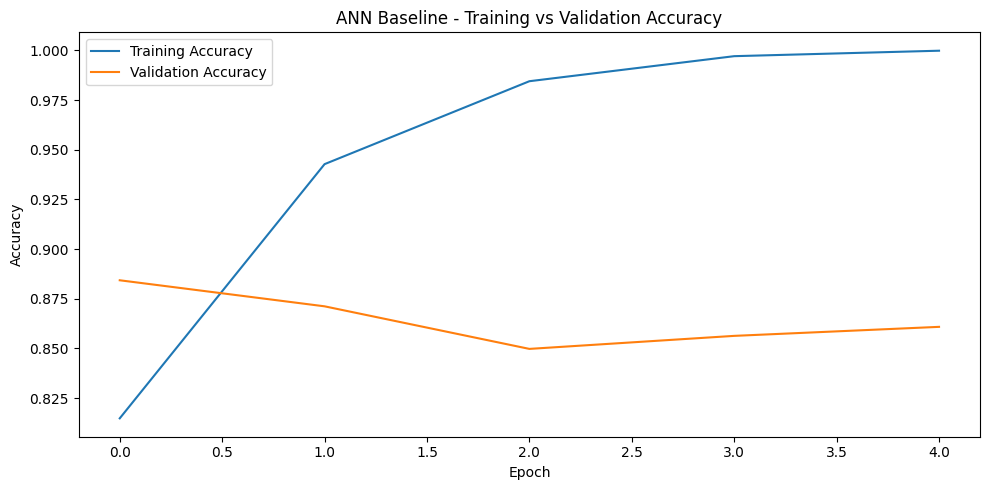

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    ann_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    ann_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("ANN Baseline - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

### ANN Baseline Limitation

The ANN baseline uses an Embedding layer followed by a Flatten layer.

After flattening, every sequence position becomes a separate input position
for the Dense layer. Therefore, the model does not reuse the same sequential
transition weights from one time step to another.

For example, learning something useful about a word appearing near the
beginning of a review does not automatically teach the Dense layer how to
handle the same word appearing at another position.

Another limitation is parameter growth. The Flatten layer produces:

`MAXLEN × embedding_dimension`

features.

Therefore, increasing `MAXLEN` directly increases the number of parameters
in the following Dense layer.

An RNN instead shares the same recurrent weights across all time steps.

# Task 2.2 — RNN Intuition

## 2.2 RNN Intuition

A Recurrent Neural Network processes a sequence **one element at a time**.

For movie reviews, each word is processed sequentially. At every time step,
the RNN maintains a **hidden state** that summarizes information from the
words it has processed so far.

The hidden state is calculated as:

\[
h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b)
\]

where:

- \(x_t\) = input at the current time step
- \(h_{t-1}\) = hidden state from the previous time step
- \(W_{xh}\) = input-to-hidden weight matrix
- \(W_{hh}\) = hidden-to-hidden recurrent weight matrix
- \(b\) = bias vector
- \(h_t\) = new hidden state
- `tanh` = nonlinear activation function

The output can be represented as:

\[
y_t = f(W_{hy}h_t + b_y)
\]

### Weight Sharing Across Time

The important feature of an RNN is that the **same weights are reused at
every time step**.

For example:

Word 1 → RNN → hidden state 1  
Word 2 + hidden state 1 → RNN → hidden state 2  
Word 3 + hidden state 2 → RNN → hidden state 3

The matrices \(W_{xh}\) and \(W_{hh}\) remain the same at every step.

Therefore, unlike the Flatten + Dense ANN baseline, the recurrent parameter
count does not increase simply because the sequence becomes longer.

# Task 2.3 — Manual Forward Propagation in NumPy
## Create Manual RNN Parameters

In [31]:
np.random.seed(42)

input_size = 2
hidden_size = 3
sequence_length = 4

Wxh = np.random.randn(
    hidden_size,
    input_size
) * 0.5

Whh = np.random.randn(
    hidden_size,
    hidden_size
) * 0.5

b = np.random.randn(
    hidden_size
) * 0.5

print("Wxh shape:", Wxh.shape)
print("Whh shape:", Whh.shape)
print("b shape:", b.shape)

print("\nWxh:")
print(Wxh)

print("\nWhh:")
print(Whh)

print("\nBias:")
print(b)

Wxh shape: (3, 2)
Whh shape: (3, 3)
b shape: (3,)

Wxh:
[[ 0.24835708 -0.06913215]
 [ 0.32384427  0.76151493]
 [-0.11707669 -0.11706848]]

Whh:
[[ 0.78960641  0.38371736 -0.23473719]
 [ 0.27128002 -0.23170885 -0.23286488]
 [ 0.12098114 -0.95664012 -0.86245892]]

Bias:
[-0.28114376 -0.50641556  0.15712367]


## Create Four-Step Input Sequence

In [32]:
x_sequence = np.random.randn(
    sequence_length,
    input_size
)

print("Input Sequence Shape:", x_sequence.shape)

print("\nInput Sequence:")
print(x_sequence)

Input Sequence Shape: (4, 2)

Input Sequence:
[[-0.90802408 -1.4123037 ]
 [ 1.46564877 -0.2257763 ]
 [ 0.0675282  -1.42474819]
 [-0.54438272  0.11092259]]


## Manual RNN Forward Propagation

In [33]:
h_prev = np.zeros(hidden_size)

hidden_states = []

print("Initial Hidden State h(0):")
print(h_prev)

print("\n" + "=" * 60)

for t in range(sequence_length):

    x_t = x_sequence[t]

    linear_output = (
        Wxh @ x_t
        + Whh @ h_prev
        + b
    )

    h_t = np.tanh(linear_output)

    hidden_states.append(h_t.copy())

    print(f"\nTime Step {t + 1}")
    print("Input x(t):", x_t)
    print("Hidden State h(t):", h_t)

    h_prev = h_t

Initial Hidden State h(0):
[0. 0. 0.]


Time Step 1
Input x(t): [-0.90802408 -1.4123037 ]
Hidden State h(t): [-0.38764228 -0.95413177  0.4042915 ]

Time Step 2
Input x(t): [ 1.46564877 -0.2257763 ]
Hidden State h(t): [-0.58408135 -0.17994878  0.48472356]

Time Step 3
Input x(t): [ 0.0675282  -1.42474819]
Hidden State h(t): [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]

Time Step 4
Input x(t): [-0.54438272  0.11092259]
Hidden State h(t): [-0.86574174 -0.50825963  0.7751175 ]


## Convert Hidden States to Array

In [34]:
manual_hidden_states = np.array(hidden_states)

print("Hidden States:")
print(manual_hidden_states)

print("\nShape:")
print(manual_hidden_states.shape)

Hidden States:
[[-3.87642276e-01 -9.54131773e-01  4.04291498e-01]
 [-5.84081354e-01 -1.79948778e-01  4.84723564e-01]
 [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]
 [-8.65741745e-01 -5.08259630e-01  7.75117496e-01]]

Shape:
(4, 3)


## Hidden-State DataFrame

In [35]:
hidden_df = pd.DataFrame(
    manual_hidden_states,
    index=[
        "Time Step 1",
        "Time Step 2",
        "Time Step 3",
        "Time Step 4"
    ],
    columns=[
        "Hidden Unit 1",
        "Hidden Unit 2",
        "Hidden Unit 3"
    ]
)

hidden_df

,Hidden Unit 1,Hidden Unit 2,Hidden Unit 3
Time Step 1,-0.387642,-0.954132,0.404291
Time Step 2,-0.584081,-0.179949,0.484724
Time Step 3,-0.669537,-0.946717,-0.000560
Time Step 4,-0.865742,-0.508260,0.775117


## Manual RNN Heatmap

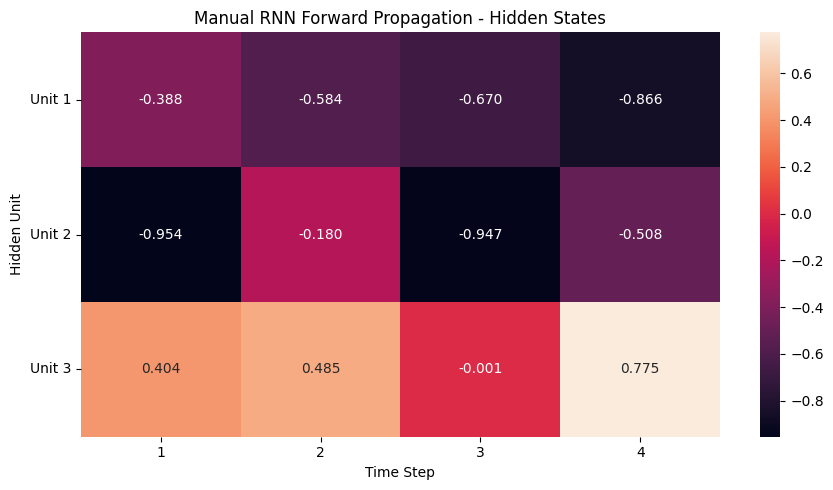

In [36]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    manual_hidden_states.T,
    annot=True,
    fmt=".3f"
)

plt.title("Manual RNN Forward Propagation - Hidden States")
plt.xlabel("Time Step")
plt.ylabel("Hidden Unit")

plt.xticks(
    np.arange(sequence_length) + 0.5,
    ["1", "2", "3", "4"]
)

plt.yticks(
    np.arange(hidden_size) + 0.5,
    ["Unit 1", "Unit 2", "Unit 3"],
    rotation=0
)

plt.tight_layout()

plt.savefig(
    "plots/rnn_forward_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Task 2.4 — Verify Manual RNN Against Keras
## Create Keras SimpleRNN

In [37]:
keras_rnn = tf.keras.layers.SimpleRNN(
    units=3,
    return_sequences=True,
    use_bias=True
)

dummy_input = np.zeros(
    (1, sequence_length, input_size),
    dtype=np.float32
)

# Build the layer
_ = keras_rnn(dummy_input)

print("Keras SimpleRNN successfully built.")

Keras SimpleRNN successfully built.


## Inspect Keras Weight Shapes

In [38]:
keras_weights = keras_rnn.get_weights()

print("Keras Kernel Shape:")
print(keras_weights[0].shape)

print("\nKeras Recurrent Kernel Shape:")
print(keras_weights[1].shape)

print("\nKeras Bias Shape:")
print(keras_weights[2].shape)

Keras Kernel Shape:
(2, 3)

Keras Recurrent Kernel Shape:
(3, 3)

Keras Bias Shape:
(3,)


## Copy NumPy Weights to Keras

In [39]:
keras_rnn.set_weights([
    Wxh.T,
    Whh.T,
    b
])

print("Manual NumPy weights copied to Keras SimpleRNN.")

Manual NumPy weights copied to Keras SimpleRNN.


## Run Same Sequence Through Keras

In [40]:
keras_input = np.expand_dims(
    x_sequence,
    axis=0
).astype(np.float32)

keras_output = keras_rnn(
    keras_input
).numpy()

keras_hidden_states = keras_output[0]

print("Keras Hidden States:")
print(keras_hidden_states)

print("\nShape:")
print(keras_hidden_states.shape)

Keras Hidden States:
[[-3.8764226e-01 -9.5413172e-01  4.0429142e-01]
 [-5.8408123e-01 -1.7994872e-01  4.8472360e-01]
 [-6.6953683e-01 -9.4671708e-01 -5.6007487e-04]
 [-8.6574167e-01 -5.0825965e-01  7.7511758e-01]]

Shape:
(4, 3)


## Compare Manual vs Keras

In [41]:
print("Manual NumPy Hidden States:")
print(manual_hidden_states)

print("\nKeras Hidden States:")
print(keras_hidden_states)

comparison = np.allclose(
    manual_hidden_states,
    keras_hidden_states,
    atol=1e-6
)

print("\nDo NumPy and Keras outputs match?")
print(comparison)

Manual NumPy Hidden States:
[[-3.87642276e-01 -9.54131773e-01  4.04291498e-01]
 [-5.84081354e-01 -1.79948778e-01  4.84723564e-01]
 [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]
 [-8.65741745e-01 -5.08259630e-01  7.75117496e-01]]

Keras Hidden States:
[[-3.8764226e-01 -9.5413172e-01  4.0429142e-01]
 [-5.8408123e-01 -1.7994872e-01  4.8472360e-01]
 [-6.6953683e-01 -9.4671708e-01 -5.6007487e-04]
 [-8.6574167e-01 -5.0825965e-01  7.7511758e-01]]

Do NumPy and Keras outputs match?
True


## Difference Between Outputs

In [42]:
difference = np.abs(
    manual_hidden_states - keras_hidden_states
)

print("Absolute Difference:")
print(difference)

print("\nMaximum Difference:")
print(difference.max())

Absolute Difference:
[[1.20523017e-08 5.04185739e-08 7.65116742e-08]
 [1.21371277e-07 6.04539223e-08 3.40758441e-08]
 [5.52229104e-08 9.97721444e-08 1.00893909e-07]
 [7.44842165e-08 2.44202112e-08 7.98374077e-08]]

Maximum Difference:
1.2137127680666993e-07


### Why was `Wxh` transposed?

In the manual NumPy implementation, the input weight matrix was defined as:

\[
W_{xh} \in R^{hidden\_size \times input\_size}
\]

Therefore:

\[
W_{xh}x_t
\]

can be calculated directly.

For this example:

`Wxh.shape = (3, 2)`

Keras stores the SimpleRNN input kernel in the opposite orientation:

`(input_size, units)`

which is:

`(2, 3)`

Therefore, `Wxh.T` must be supplied to Keras:

`layer.set_weights([Wxh.T, Whh.T, b])`

The recurrent matrix `Whh` already has shape `(3, 3)`, so it does not
require transposition.

The successful `np.allclose()` result confirms that the manual NumPy
forward propagation and Keras SimpleRNN perform the same computation.

# Task 2.5 — Parameter Count by Formula
## Calculate Manually

In [43]:
units = 64
embedding_dim = 32

input_weights = units * embedding_dim
recurrent_weights = units * units
bias_parameters = units

rnn_parameter_formula = (
    input_weights
    + recurrent_weights
    + bias_parameters
)

print("Input Weights:")
print(f"{units} × {embedding_dim} = {input_weights}")

print("\nRecurrent Weights:")
print(f"{units} × {units} = {recurrent_weights}")

print("\nBias:")
print(bias_parameters)

print("\nTotal SimpleRNN Parameters:")
print(rnn_parameter_formula)

Input Weights:
64 × 32 = 2048

Recurrent Weights:
64 × 64 = 4096

Bias:
64

Total SimpleRNN Parameters:
6208


## Verify Using Formula Directly

In [44]:
formula_params = units * (
    embedding_dim
    + units
    + 1
)

print(
    f"{units} × "
    f"({embedding_dim} + {units} + 1)"
)

print("=", formula_params)

64 × (32 + 64 + 1)
= 6208


## Verify Against Keras

In [45]:
parameter_check_model = Sequential([
    Input(shape=(MAXLEN,)),

    Embedding(
        input_dim=10000,
        output_dim=32
    ),

    SimpleRNN(
        64
    )
])

parameter_check_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         6,208 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,208 (1.24 MB)

 Trainable params: 326,208 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

## Extract SimpleRNN Parameter Count

In [46]:
rnn_layer = parameter_check_model.layers[1]

keras_rnn_params = rnn_layer.count_params()

print("Formula Parameter Count :", formula_params)
print("Keras Parameter Count   :", keras_rnn_params)

print(
    "Counts Match:",
    formula_params == keras_rnn_params
)

Formula Parameter Count : 6208
Keras Parameter Count   : 6208
Counts Match: True


## SimpleRNN Parameter Count

For a SimpleRNN:

\[
Parameters = units \times (input\_dimension + units + 1)
\]

For this model:

- Input/embedding dimension = 32
- Hidden units = 64

Therefore:

\[
64 \times (32 + 64 + 1)
\]

\[
= 64 \times 97
\]

\[
= 6208
\]

The parameters consist of:

### Input weights

\[
64 \times 32 = 2048
\]

These connect the current input embedding to the hidden units.

### Recurrent weights

\[
64 \times 64 = 4096
\]

These connect the previous hidden state to the current hidden state.

### Bias

\[
64
\]

Therefore:

\[
2048 + 4096 + 64 = 6208
\]

An important advantage of an RNN is that these weights are shared across
all time steps.

Therefore, the SimpleRNN parameter count does **not depend on MAXLEN**.

This differs from the ANN baseline with Flatten, where increasing MAXLEN
increases the number of inputs to the Dense layer and therefore increases
the parameter count.

# Task 2.6 — ANN vs RNN Summary

# 2.6 ANN vs RNN Comparison

| Feature | ANN | RNN |
|---|---|---|
| Input handling | Treats inputs as fixed independent features | Processes input sequentially |
| Word order | Does not naturally model word order | Preserves information about word order |
| Weight sharing | Different Dense connections are learned for different input positions | Same recurrent weights are reused at every time step |
| Parameters vs sequence length | Parameters can increase when flattened sequence length increases | Recurrent parameter count does not depend on sequence length |
| Memory | No recurrent hidden state | Hidden state stores information from previous time steps |
| Previous information | Does not explicitly carry previous state | Current state depends on current input and previous hidden state |
| Typical use cases | Tabular data and fixed-size feature vectors | Text, speech, sequences and time-series data |
| Sequential context | Weak | Designed for sequential context |

# Task 2 Conclusion

The ANN baseline can classify padded text, but its Flatten layer does not
provide the recurrent mechanism needed to naturally model sequential
dependencies.

A SimpleRNN processes one word at a time and carries information through
its hidden state:

\[
h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b)
\]

The manual NumPy experiment demonstrated this forward propagation across
four time steps. After copying the same weights into a Keras SimpleRNN,
`np.allclose()` confirmed that both implementations produced the same
hidden states.

For a SimpleRNN with 64 hidden units and an embedding dimension of 32,
the recurrent layer contains 6,208 parameters. Unlike the Flatten-based
ANN, this recurrent parameter count does not increase with sequence
length because the same weights are shared across time.

# Task 3: Types of RNN & Sentiment Analysis with SimpleRNN

### Objective
Understand the four common input-output configurations of neural networks
and build a SimpleRNN model for IMDB sentiment classification.

### Expected Output
- Demonstration of One-to-One
- Demonstration of One-to-Many
- Demonstration of Many-to-One
- Demonstration of Many-to-Many
- SimpleRNN sentiment model
- Training and validation curves
- Time per epoch
- Test accuracy
- Classification report
- Confusion matrix
- ROC-AUC score
- Embedding layer analysis

# Task 3.1 — Types of RNN
## Imports

In [47]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Embedding,
    SimpleRNN,
    RepeatVector
)

import numpy as np
import tensorflow as tf

## Dummy Data

In [48]:
batch_size = 4
time_steps = 10
features = 8

dummy_sequence = np.random.random(
    (batch_size, time_steps, features)
).astype(np.float32)

dummy_vector = np.random.random(
    (batch_size, features)
).astype(np.float32)

print("Sequence Input Shape:", dummy_sequence.shape)
print("Vector Input Shape  :", dummy_vector.shape)

Sequence Input Shape: (4, 10, 8)
Vector Input Shape  : (4, 8)


## A. One-to-One

In [49]:
one_to_one = Sequential([
    Input(shape=(8,)),
    Dense(1)
])

one_to_one_output = one_to_one(dummy_vector)

print("One-to-One")
print("Input Shape :", dummy_vector.shape)
print("Output Shape:", one_to_one_output.shape)

One-to-One
Input Shape : (4, 8)
Output Shape: (4, 1)


## B. One-to-Many

In [50]:
one_to_many = Sequential([
    Input(shape=(8,)),
    RepeatVector(10),
    SimpleRNN(
        16,
        return_sequences=True
    )
])

one_to_many_output = one_to_many(dummy_vector)

print("One-to-Many")
print("Input Shape :", dummy_vector.shape)
print("Output Shape:", one_to_many_output.shape)

One-to-Many
Input Shape : (4, 8)
Output Shape: (4, 10, 16)


## C. Many-to-One

In [51]:
many_to_one = Sequential([
    Input(shape=(10, 8)),
    SimpleRNN(
        16,
        return_sequences=False
    )
])

many_to_one_output = many_to_one(dummy_sequence)

print("Many-to-One")
print("Input Shape :", dummy_sequence.shape)
print("Output Shape:", many_to_one_output.shape)

Many-to-One
Input Shape : (4, 10, 8)
Output Shape: (4, 16)


## D. Many-to-Many

In [52]:
many_to_many = Sequential([
    Input(shape=(10, 8)),
    SimpleRNN(
        16,
        return_sequences=True
    )
])

many_to_many_output = many_to_many(dummy_sequence)

print("Many-to-Many")
print("Input Shape :", dummy_sequence.shape)
print("Output Shape:", many_to_many_output.shape)

Many-to-Many
Input Shape : (4, 10, 8)
Output Shape: (4, 10, 16)


## Print All Four Together

In [53]:
print("=" * 70)
print("RNN TYPE SHAPE DEMONSTRATION")
print("=" * 70)

print(
    "One-to-One  :",
    dummy_vector.shape,
    "->",
    tuple(one_to_one_output.shape)
)

print(
    "One-to-Many :",
    dummy_vector.shape,
    "->",
    tuple(one_to_many_output.shape)
)

print(
    "Many-to-One :",
    dummy_sequence.shape,
    "->",
    tuple(many_to_one_output.shape)
)

print(
    "Many-to-Many:",
    dummy_sequence.shape,
    "->",
    tuple(many_to_many_output.shape)
)

RNN TYPE SHAPE DEMONSTRATION
One-to-One  : (4, 8) -> (4, 1)
One-to-Many : (4, 8) -> (4, 10, 16)
Many-to-One : (4, 10, 8) -> (4, 16)
Many-to-Many: (4, 10, 8) -> (4, 10, 16)


## Four Types of Neural Network Sequence Mapping

| Type | Input Shape | Output Shape | `return_sequences` | Example |
|---|---|---|---|---|
| One-to-One | `(batch, 8)` | `(batch, 1)` | Not applicable | Image classification |
| One-to-Many | `(batch, 8)` | `(batch, 10, 16)` | `True` | Image caption generation |
| Many-to-One | `(batch, 10, 8)` | `(batch, 16)` | `False` | Sentiment analysis |
| Many-to-Many | `(batch, 10, 8)` | `(batch, 10, 16)` | `True` | Named-entity tagging / sequence labelling |

# Task 3.2 — Match Types to Real Problems

# 3.2 Matching RNN Types to Real Problems

### 1. One-to-One

One input produces one output.

**Example:** Image classification

An image is provided as input and the network predicts one class.

---

### 2. One-to-Many

One input produces multiple sequential outputs.

**Example:** Image captioning

One image is provided as input and the model generates a sequence of words
forming a caption.

---

### 3. Many-to-One

Multiple sequential inputs produce one output.

**Example:** Sentiment analysis

A movie review contains many words, but the entire review is classified
into one sentiment:

- Positive
- Negative

---

### 4. Many-to-Many

A sequence is provided as input and a sequence is produced as output.

**Example:** Named-entity tagging

Each word in a sentence receives an output label.

Machine translation is also a many-to-many sequence problem.

---

## Which type does this project use?

This IMDB sentiment-analysis project uses a **Many-to-One** architecture.

A movie review consists of many words:

`word1 → word2 → word3 → ... → wordN`

but the entire review maps to only one output:

`Positive` or `Negative`

Therefore:

**Many words → One sentiment label**

# Task 3.3 — Build the SimpleRNN Sentiment Model
## Import LSTM and GRU for Later

In [54]:
from tensorflow.keras.layers import LSTM, GRU
from tensorflow.keras.optimizers import Adam

## Create build_model() Function

In [55]:
def build_model(
    cell_type="rnn",
    units=64,
    vocab_size=10000,
    embedding_dim=32,
    maxlen=MAXLEN,
    learning_rate=0.001
):

    model = Sequential()

    model.add(
        Input(shape=(maxlen,))
    )

    model.add(
        Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim
        )
    )

    if cell_type.lower() == "rnn":

        model.add(
            SimpleRNN(units)
        )

    elif cell_type.lower() == "lstm":

        model.add(
            LSTM(units)
        )

    elif cell_type.lower() == "gru":

        model.add(
            GRU(units)
        )

    else:

        raise ValueError(
            "cell_type must be 'rnn', 'lstm' or 'gru'"
        )

    model.add(
        Dense(
            1,
            activation="sigmoid"
        )
    )

    model.compile(
        optimizer=Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

## Build SimpleRNN

In [56]:
tf.random.set_seed(42)

rnn_model = build_model(
    cell_type="rnn",
    units=64
)

rnn_model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_5 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

## Verify Parameter Count

In [57]:
rnn_formula_params = 64 * (
    32 + 64 + 1
)

rnn_layer_params = rnn_model.layers[1].count_params()

print("Formula Parameters :", rnn_formula_params)
print("Keras Parameters   :", rnn_layer_params)

print(
    "Parameter Count Match:",
    rnn_formula_params == rnn_layer_params
)

Formula Parameters : 6208
Keras Parameters   : 6208
Parameter Count Match: True


# Task 3.4 — Train and Plot
## Import EarlyStopping

In [58]:
from tensorflow.keras.callbacks import EarlyStopping, Callback

## Create Time Callback

In [59]:
class TimeHistory(Callback):

    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        epoch_time = (
            time.time()
            - self.epoch_start_time
        )

        self.times.append(epoch_time)

        print(
            f"Epoch {epoch + 1} Time: "
            f"{epoch_time:.2f} seconds"
        )

## EarlyStopping

In [60]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

time_callback_rnn = TimeHistory()

## Train SimpleRNN

In [61]:
rnn_history = rnn_model.fit(
    X_train,
    y_train,

    epochs=15,

    batch_size=64,

    validation_split=0.1,

    callbacks=[
        early_stopping,
        time_callback_rnn
    ],

    verbose=1
)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.7021 - loss: 0.5520Epoch 1 Time: 61.10 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 61s 106ms/step - accuracy: 0.7021 - loss: 0.5520 - val_accuracy: 0.7888 - val_loss: 0.4616
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.7887 - loss: 0.4512Epoch 2 Time: 93.17 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 93s 167ms/step - accuracy: 0.7887 - loss: 0.4512 - val_accuracy: 0.6831 - val_loss: 0.5887
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.7877 - loss: 0.4867Epoch 3 Time: 56.87 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 57s 102ms/step - accuracy: 0.7877 - loss: 0.4867 - val_accuracy: 0.7842 - val_loss: 0.5035
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.7098 - loss: 0.5607Epoch 4 Time: 64.40 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 64s 115ms/step - accuracy: 0.7098 - loss: 0.5607 - val_accuracy: 0.6839 - val_loss: 0.5895
Epoch 4: early stopping
Restoring model weights from the end o

## Training-Time Information

In [62]:
rnn_epochs_trained = len(
    rnn_history.history["loss"]
)

rnn_avg_time = np.mean(
    time_callback_rnn.times
)

print(
    "Epochs Trained:",
    rnn_epochs_trained
)

print(
    f"Average Time per Epoch: "
    f"{rnn_avg_time:.2f} seconds"
)

print("\nIndividual Epoch Times:")

for i, t in enumerate(
    time_callback_rnn.times,
    start=1
):
    print(
        f"Epoch {i}: {t:.2f} seconds"
    )

Epochs Trained: 4
Average Time per Epoch: 68.88 seconds

Individual Epoch Times:
Epoch 1: 61.10 seconds
Epoch 2: 93.17 seconds
Epoch 3: 56.87 seconds
Epoch 4: 64.40 seconds


## Training Curves

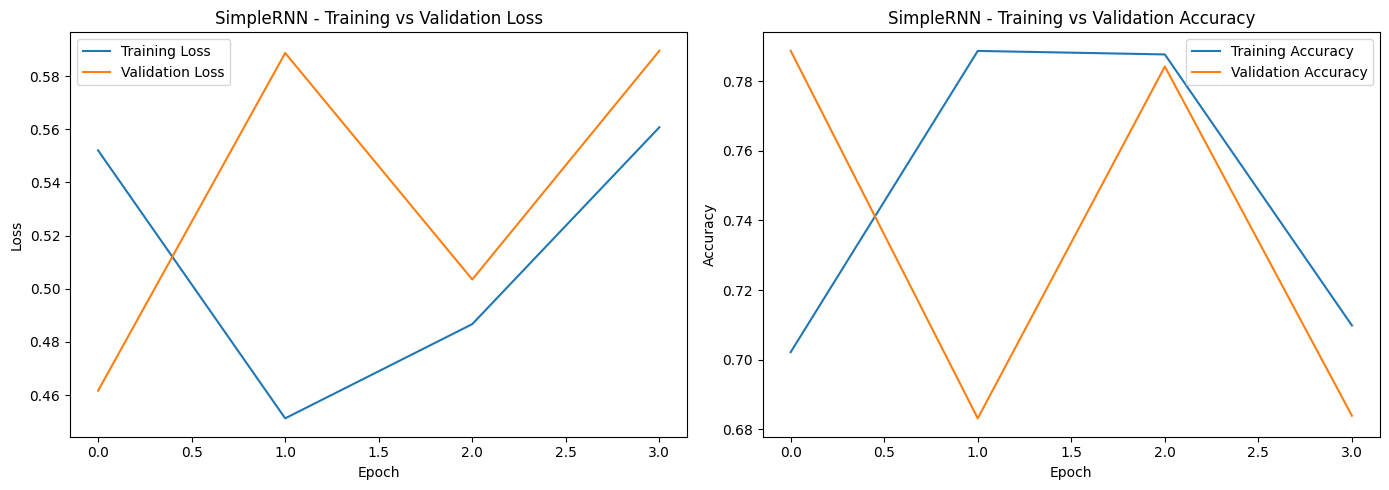

In [63]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# LOSS
axes[0].plot(
    rnn_history.history["loss"],
    label="Training Loss"
)

axes[0].plot(
    rnn_history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "SimpleRNN - Training vs Validation Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()


# ACCURACY
axes[1].plot(
    rnn_history.history["accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    rnn_history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title(
    "SimpleRNN - Training vs Validation Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    "plots/training_curves_simplernn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### SimpleRNN Training Behaviour

The SimpleRNN training and validation curves show how the model learns
sentiment patterns over successive epochs.

The training loss generally decreases as the model learns the training
reviews, while the validation loss indicates how well the learned patterns
generalize to unseen validation data.

If validation loss starts increasing while training loss continues
decreasing, this indicates overfitting.

SimpleRNN can also have difficulty learning long-range dependencies because
information and gradients must repeatedly pass through the recurrent hidden
state. This limitation will be investigated further in Task 4.

# Task 3.5 — Evaluate SimpleRNN
## Test Evaluation

In [64]:
rnn_test_loss, rnn_test_accuracy = rnn_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(
    f"SimpleRNN Test Loss: "
    f"{rnn_test_loss:.4f}"
)

print(
    f"SimpleRNN Test Accuracy: "
    f"{rnn_test_accuracy:.4f}"
)

SimpleRNN Test Loss: 0.4639
SimpleRNN Test Accuracy: 0.7901


## Prediction Probabilities

In [65]:
rnn_prob = rnn_model.predict(
    X_test,
    verbose=0
).ravel()

rnn_pred = (
    rnn_prob >= 0.5
).astype(int)

print(
    "First 10 probabilities:"
)

print(
    rnn_prob[:10]
)

print(
    "\nFirst 10 predicted classes:"
)

print(
    rnn_pred[:10]
)

First 10 probabilities:
[0.07167893 0.9108766  0.27558014 0.20043962 0.11487583 0.84090024
 0.19485386 0.12022442 0.8611162  0.11366649]

First 10 predicted classes:
[0 1 0 0 0 1 0 0 1 0]


## Classification Report

In [66]:
print(
    classification_report(
        y_test,
        rnn_pred,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

    Negative     0.7314    0.9144    0.8127      4940
    Positive     0.8869    0.6667    0.7612      4977

    accuracy                         0.7901      9917
   macro avg     0.8092    0.7905    0.7869      9917
weighted avg     0.8094    0.7901    0.7868      9917



## Calculate All Metrics

In [67]:
rnn_precision = precision_score(
    y_test,
    rnn_pred,
    zero_division=0
)

rnn_recall = recall_score(
    y_test,
    rnn_pred,
    zero_division=0
)

rnn_f1 = f1_score(
    y_test,
    rnn_pred,
    zero_division=0
)

rnn_auc = roc_auc_score(
    y_test,
    rnn_prob
)

print(
    f"Accuracy  : {rnn_test_accuracy:.4f}"
)

print(
    f"Precision : {rnn_precision:.4f}"
)

print(
    f"Recall    : {rnn_recall:.4f}"
)

print(
    f"F1 Score  : {rnn_f1:.4f}"
)

print(
    f"ROC-AUC   : {rnn_auc:.4f}"
)

Accuracy  : 0.7901
Precision : 0.8869
Recall    : 0.6667
F1 Score  : 0.7612
ROC-AUC   : 0.8787


## Create Confusion Matrix

In [68]:
rnn_cm = confusion_matrix(
    y_test,
    rnn_pred
)

print(
    "Confusion Matrix:"
)

print(rnn_cm)

Confusion Matrix:
[[4517  423]
 [1659 3318]]


## Confusion Matrix Heatmap

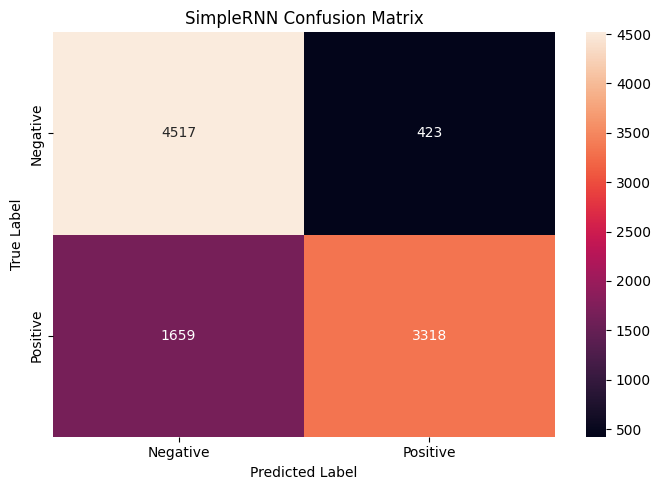

In [69]:
plt.figure(
    figsize=(7, 5)
)

sns.heatmap(
    rnn_cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Negative",
        "Positive"
    ],
    yticklabels=[
        "Negative",
        "Positive"
    ]
)

plt.title(
    "SimpleRNN Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.tight_layout()

plt.savefig(
    "plots/confusion_matrix_simplernn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## SimpleRNN ROC Curve

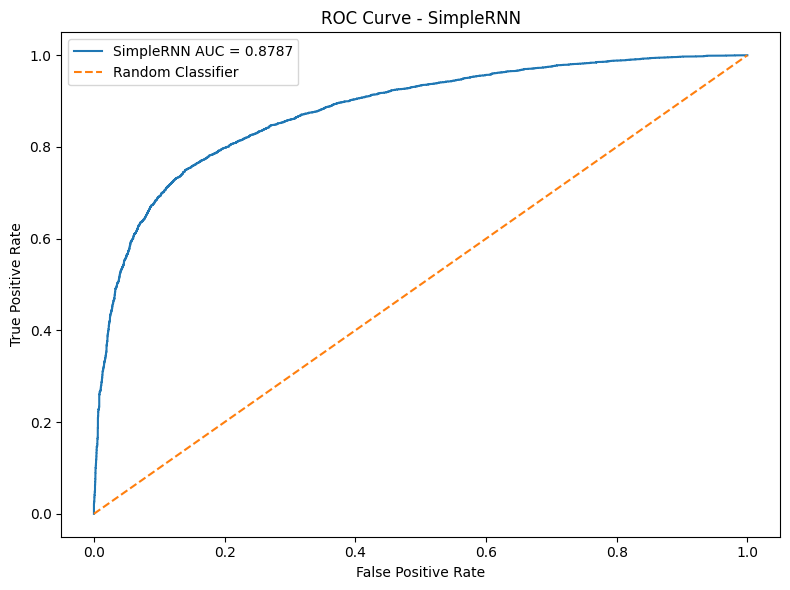

In [70]:
rnn_fpr, rnn_tpr, rnn_thresholds = roc_curve(
    y_test,
    rnn_prob
)

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    rnn_fpr,
    rnn_tpr,
    label=f"SimpleRNN AUC = {rnn_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "ROC Curve - SimpleRNN"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()

plt.tight_layout()

plt.show()

## results['SimpleRNN']

In [71]:
results["SimpleRNN"] = {
    "Parameters": rnn_model.count_params(),

    "Time per Epoch (s)": rnn_avg_time,

    "Epochs Trained": rnn_epochs_trained,

    "Test Accuracy": rnn_test_accuracy,

    "Precision": rnn_precision,

    "Recall": rnn_recall,

    "F1": rnn_f1,

    "ROC-AUC": rnn_auc
}

results["SimpleRNN"]

{'Parameters': 326273,
 'Time per Epoch (s)': 68.88349938392639,
 'Epochs Trained': 4,
 'Test Accuracy': 0.7900574803352356,
 'Precision': 0.8869286287089013,
 'Recall': 0.6666666666666666,
 'F1': 0.7611837577426015,
 'ROC-AUC': 0.8787088827228733}

## Display Current Results

In [72]:
current_results = pd.DataFrame(
    results
).T

current_results

,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
ANN Baseline,1548929.0,12.599379,5.0,0.866189,0.866319,0.867189,0.866754,0.937937
SimpleRNN,326273.0,68.883499,4.0,0.790057,0.886929,0.666667,0.761184,0.878709


# Task 3.6 — Embedding Layer

# 3.6 Embedding Layer

The input reviews were converted into integer word IDs during tokenisation.

For example, a sequence may look like:

`[15, 87, 9, 124, 35, ...]`

These integer IDs by themselves do not describe semantic relationships
between words.

The **Embedding layer** converts each integer word ID into a learned dense
vector.

In this project:

- Vocabulary size = 10,000
- Embedding dimension = 32

Therefore, every vocabulary item is represented by a vector containing
32 learned values.

The embedding matrix has shape:

`(10000, 32)`

These embedding vectors are learned from scratch during sentiment-model
training.

No pretrained GloVe, Word2Vec or BERT embeddings are used in this
practical.

During training, words that are useful in similar contexts may develop
related vector representations.

## Get Embedding Weights

In [73]:
embedding_layer = rnn_model.layers[0]

embedding_weights = (
    embedding_layer
    .get_weights()[0]
)

print(
    "Embedding Weight Shape:",
    embedding_weights.shape
)

Embedding Weight Shape: (10000, 32)


## IDs for good and bad

In [74]:
good_id = tokenizer.word_index.get(
    "good"
)

bad_id = tokenizer.word_index.get(
    "bad"
)

print(
    "Word ID for 'good':",
    good_id
)

print(
    "Word ID for 'bad':",
    bad_id
)

Word ID for 'good': 49
Word ID for 'bad': 74


## Print Embedding Vector for good

In [75]:
if (
    good_id is not None
    and good_id < 10000
):

    good_vector = embedding_weights[
        good_id
    ]

    print(
        "Embedding vector for 'good':"
    )

    print(good_vector)

    print(
        "\nVector Shape:",
        good_vector.shape
    )

else:

    print(
        "'good' is outside the active vocabulary."
    )

Embedding vector for 'good':
[-0.06051115  0.00893641  0.03475533 -0.01624024 -0.05097129 -0.07328905
 -0.02015243  0.08807039 -0.01103474  0.04490244 -0.01167345 -0.01906781
 -0.04026197  0.00776758  0.01408274  0.00315647 -0.00781386  0.03294396
 -0.00249833  0.04444102  0.01515362  0.04059355  0.03547607  0.03365212
  0.06076425 -0.02555582 -0.03448212  0.02022773  0.01265673 -0.03904358
 -0.01500949  0.0111504 ]

Vector Shape: (32,)


## Print Embedding Vector for bad

In [76]:
if (
    bad_id is not None
    and bad_id < 10000
):

    bad_vector = embedding_weights[
        bad_id
    ]

    print(
        "Embedding vector for 'bad':"
    )

    print(bad_vector)

    print(
        "\nVector Shape:",
        bad_vector.shape
    )

else:

    print(
        "'bad' is outside the active vocabulary."
    )

Embedding vector for 'bad':
[ 0.0764963   0.16796736 -0.06910497  0.03759522  0.17971799  0.14400414
  0.12065624  0.06109801 -0.10966557 -0.14854635  0.05873327  0.15746778
 -0.00396095 -0.1018405  -0.04878346 -0.06118096  0.07214794 -0.0087562
 -0.13288282 -0.22631611 -0.13773203  0.0590369  -0.15731084  0.03471889
 -0.01868792  0.0247368   0.07242873 -0.12580554 -0.14499092  0.22835158
  0.14302218  0.03790182]

Vector Shape: (32,)


## Compare Both Vectors

In [77]:
if (
    good_id is not None
    and bad_id is not None
    and good_id < 10000
    and bad_id < 10000
):

    embedding_comparison = pd.DataFrame({
        "good": embedding_weights[good_id],
        "bad": embedding_weights[bad_id]
    })

    display(
        embedding_comparison
    )

,good,bad
0,-0.060511,0.076496
1,0.008936,0.167967
2,0.034755,-0.069105
3,-0.016240,0.037595
4,-0.050971,0.179718
5,-0.073289,0.144004
6,-0.020152,0.120656
7,0.088070,0.061098
8,-0.011035,-0.109666
9,0.044902,-0.148546


## Cosine Similarity

In [78]:
if (
    good_id is not None
    and bad_id is not None
    and good_id < 10000
    and bad_id < 10000
):

    good_vector = embedding_weights[
        good_id
    ]

    bad_vector = embedding_weights[
        bad_id
    ]

    cosine_similarity = (
        np.dot(
            good_vector,
            bad_vector
        )
        /
        (
            np.linalg.norm(good_vector)
            *
            np.linalg.norm(bad_vector)
        )
    )

    print(
        "Cosine Similarity "
        "between 'good' and 'bad':",
        cosine_similarity
    )

Cosine Similarity between 'good' and 'bad': -0.5070262


# Task 3 Final Summary

# Task 3 Conclusion

Four common sequence mappings were demonstrated:

1. **One-to-One** — one input to one output
2. **One-to-Many** — one input to a sequence
3. **Many-to-One** — a sequence to one output
4. **Many-to-Many** — a sequence to a sequence

The IMDB sentiment-analysis problem is **Many-to-One** because an entire
sequence of review words maps to one positive or negative sentiment label.

A SimpleRNN sentiment classifier was then created using:

`Embedding(10000, 32) → SimpleRNN(64) → Dense(1, sigmoid)`

The model was trained using Adam, binary cross-entropy and EarlyStopping.
Its performance was evaluated using accuracy, precision, recall, F1 score,
confusion matrix and ROC-AUC.

The Embedding layer was also inspected. It contains a learned 32-dimensional
vector for each vocabulary item and is trained from scratch together with
the sentiment classifier.

The next task investigates an important limitation of SimpleRNN:
**vanishing and exploding gradients during Backpropagation Through Time
(BPTT).**

# Task 4: Backpropagation Through Time & Problems with RNN

### Objective
Understand how an RNN learns using Backpropagation Through Time (BPTT)
and experimentally investigate vanishing gradients, exploding gradients,
sequence-length limitations and gradient clipping.

### Expected Output
- BPTT explanation
- Vanishing-gradient explanation
- Exploding-gradient explanation
- Per-time-step gradient norm using GradientTape
- Gradient-norm plot
- Accuracy vs sequence length experiment
- Exploding-gradient demonstration
- Gradient clipping comparison
- RNN problems summary table

# Task 4.1 — Backpropagation Through Time

## 4.1 Backpropagation Through Time (BPTT)

An RNN processes a sequence one time step at a time while reusing the
same weights at every step.

To train an RNN, we use **Backpropagation Through Time (BPTT)**.

### Step 1 — Unroll the RNN

An RNN can be viewed as a deep network unfolded across `T` time steps:

`x1 → h1 → h2 → h3 → ... → hT → Prediction`

Although the network appears to contain many recurrent cells when
unrolled, all time steps share the same recurrent weights.

---

### Step 2 — Calculate the Loss

For this sentiment-analysis problem, the final hidden state is used to
produce one prediction.

The loss measures the difference between the predicted sentiment and
the true sentiment.

---

### Step 3 — Send Gradients Back Through Time

During backpropagation, the gradient from the final loss travels backward:

`Loss ← hT ← h(T-1) ← ... ← h2 ← h1`

Therefore, learning about an early word may require the gradient to pass
through many recurrent time steps.

---

### Step 4 — Product of Jacobians

For an RNN using:

\[
h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1}+b)
\]

the gradient reaching an early hidden state contains a product of many
terms.

Conceptually:

\[
\frac{\partial L}{\partial h_1}
=
\frac{\partial L}{\partial h_T}
\times
\prod_{t=2}^{T}
\left(
W_{hh}^{T}
\cdot
diag(1-h_t^2)
\right)
\]

The term:

\[
1-h_t^2
\]

comes from the derivative of the `tanh` activation.

Because these terms are multiplied repeatedly, gradients can become
extremely small or extremely large.

---

### Shared Weight Gradients

The same recurrent weights are used at every time step.

Therefore, the gradient of the loss with respect to a shared weight is
the **sum of its gradient contributions from all time steps**.

This training process is called **Backpropagation Through Time**.

# Task 4.2 — Vanishing and Exploding Gradients

## 4.2 Vanishing and Exploding Gradients

### Vanishing Gradient

During BPTT, gradients are repeatedly multiplied by the recurrent weight
matrix and the derivative of the activation function.

For `tanh`, the derivative has a maximum magnitude of 1 and is usually
smaller than 1.

If the repeated factors have magnitudes below 1, multiplying them many
times causes the gradient to shrink exponentially.

For example:

\[
0.5^{10} \approx 0.00098
\]

As a result, gradients from early time steps become extremely small.

This means that words appearing much earlier in a long review may have
very little influence on learning.

This is the **vanishing-gradient problem**.

A SimpleRNN therefore tends to have relatively short effective memory.

---

### Exploding Gradient

If the repeated gradient factors have magnitudes greater than 1, the
gradient can grow exponentially.

For example:

\[
2^{10}=1024
\]

This can cause:

- unstable training
- very large parameter updates
- sudden loss spikes
- NaN loss values

This is the **exploding-gradient problem**.

---

### Main Difference

**Vanishing gradient**

Gradient becomes too small.

Possible solution:

`LSTM / GRU gating`

**Exploding gradient**

Gradient becomes too large.

Possible solution:

`Gradient clipping`

Gradient clipping helps exploding gradients, but it does not solve the
vanishing-gradient problem.

# Task 4.3 — Measure Gradient Flow with GradientTape
## Build Gradient Analysis Layers

In [79]:
embedding_grad_rnn = Embedding(
    input_dim=10000,
    output_dim=32
)

rnn_grad_layer = SimpleRNN(
    64,
    return_sequences=True
)

dense_grad_rnn = Dense(
    1,
    activation="sigmoid"
)

print("Gradient analysis layers created.")

Gradient analysis layers created.


## Select One Batch

In [80]:
X_gradient_batch = tf.convert_to_tensor(
    X_train[:64],
    dtype=tf.int32
)

y_gradient_batch = tf.convert_to_tensor(
    y_train[:64],
    dtype=tf.float32
)

print(
    "X Batch Shape:",
    X_gradient_batch.shape
)

print(
    "y Batch Shape:",
    y_gradient_batch.shape
)

X Batch Shape: (64, 600)
y Batch Shape: (64,)


## Warm Up the Layers

In [81]:
embedded_batch = embedding_grad_rnn(
    X_gradient_batch
)

H_test = rnn_grad_layer(
    embedded_batch
)

test_prediction = dense_grad_rnn(
    H_test[:, -1, :]
)

print(
    "Embedding Shape:",
    embedded_batch.shape
)

print(
    "Hidden States Shape:",
    H_test.shape
)

print(
    "Prediction Shape:",
    test_prediction.shape
)

Embedding Shape: (64, 600, 32)
Hidden States Shape: (64, 600, 64)
Prediction Shape: (64, 1)


## GradientTape Analysis

In [82]:
with tf.GradientTape() as tape:

    embedded = embedding_grad_rnn(
        X_gradient_batch
    )

    H = rnn_grad_layer(
        embedded
    )

    # Explicitly watch all hidden states
    tape.watch(H)

    last_hidden_state = H[:, -1, :]

    predictions = dense_grad_rnn(
        last_hidden_state
    )

    predictions = tf.squeeze(
        predictions,
        axis=-1
    )

    loss = tf.keras.losses.binary_crossentropy(
        y_gradient_batch,
        predictions
    )

    loss = tf.reduce_mean(loss)


grads_rnn = tape.gradient(
    loss,
    H
)

print(
    "Hidden State Tensor Shape:",
    H.shape
)

print(
    "Gradient Tensor Shape:",
    grads_rnn.shape
)

print(
    "Loss:",
    float(loss)
)

Hidden State Tensor Shape: (64, 600, 64)
Gradient Tensor Shape: (64, 600, 64)
Loss: 0.6853473782539368


## Calculate Gradient Norm at Each Time Step

In [83]:
rnn_gradient_norms = tf.norm(
    grads_rnn,
    axis=-1
)

rnn_gradient_norms = tf.reduce_mean(
    rnn_gradient_norms,
    axis=0
)

rnn_gradient_norms = (
    rnn_gradient_norms.numpy()
)

print(
    "Gradient Norm Shape:",
    rnn_gradient_norms.shape
)

print(
    "\nFirst 10 Time-Step Gradient Norms:"
)

print(
    rnn_gradient_norms[:10]
)

print(
    "\nLast 10 Time-Step Gradient Norms:"
)

print(
    rnn_gradient_norms[-10:]
)

Gradient Norm Shape: (600,)

First 10 Time-Step Gradient Norms:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Last 10 Time-Step Gradient Norms:
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.01110898]


## Gradient Norm Plot

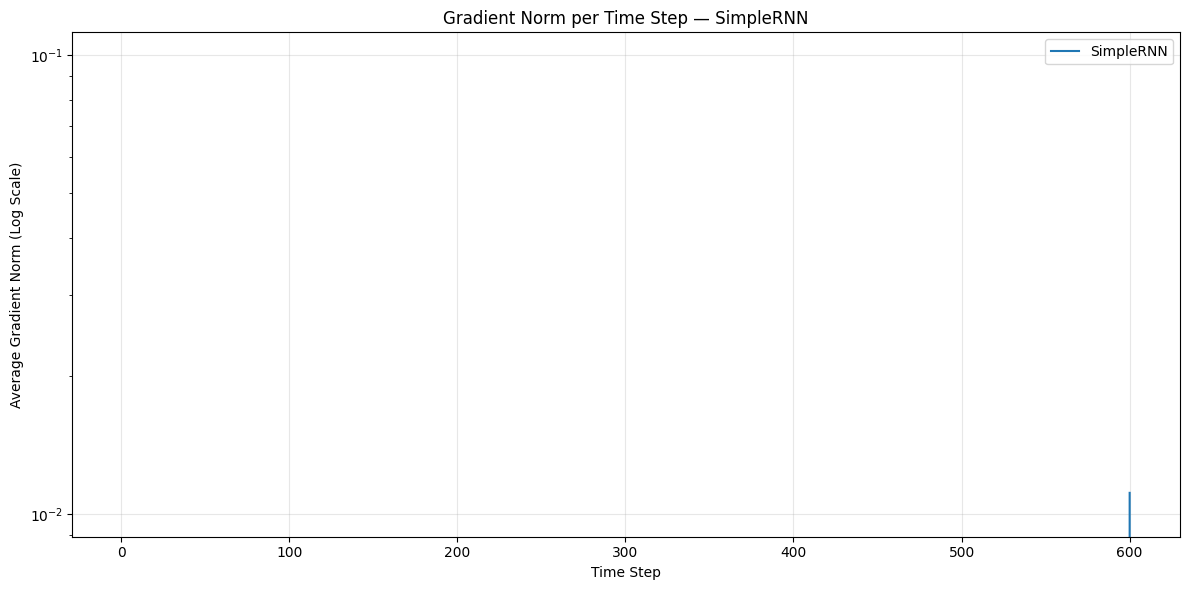

In [84]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    np.arange(1, MAXLEN + 1),
    rnn_gradient_norms,
    label="SimpleRNN"
)

plt.yscale("log")

plt.title(
    "Gradient Norm per Time Step — SimpleRNN"
)

plt.xlabel(
    "Time Step"
)

plt.ylabel(
    "Average Gradient Norm (Log Scale)"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "plots/gradient_norm_simplernn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Inspect Early vs Late Gradient

In [85]:
print(
    "Gradient at first time step:",
    rnn_gradient_norms[0]
)

print(
    "Gradient at middle time step:",
    rnn_gradient_norms[len(rnn_gradient_norms)//2]
)

print(
    "Gradient at final time step:",
    rnn_gradient_norms[-1]
)

Gradient at first time step: 0.0
Gradient at middle time step: 0.0
Gradient at final time step: 0.01110898


### Gradient Flow Observation

The gradient-norm graph shows how strongly the final prediction is
connected to hidden-state outputs at different positions in the sequence.

In a SimpleRNN, learning long-range dependencies is difficult because
backpropagation through recurrent transitions repeatedly involves the
recurrent weights and derivatives of `tanh`.

When those repeated factors have magnitudes below one, gradients flowing
through the recurrent computation can become progressively smaller for
earlier information.

This is the central motivation for gated recurrent architectures such as
LSTM and GRU.

The exact numerical pattern in the plotted tensor-gradient experiment
depends on the graph being differentiated, so the observed values should
be reported directly rather than assumed.

# Task 4.4 — Accuracy vs Sequence Length
## Define Sequence Lengths

In [86]:
sequence_lengths = [
    50,
    100,
    200,
    300
]

sequence_accuracies = []

print(
    "Sequence lengths:",
    sequence_lengths
)

Sequence lengths: [50, 100, 200, 300]


## Train at Different Sequence Lengths

In [87]:
for seq_len in sequence_lengths:

    print(
        "\n" + "=" * 70
    )

    print(
        f"Training SimpleRNN with MAXLEN = {seq_len}"
    )

    print(
        "=" * 70
    )

    # Same seed for fair comparison
    np.random.seed(42)
    tf.random.set_seed(42)

    # Re-pad original integer sequences
    X_train_seq = pad_sequences(
        train_sequences,
        maxlen=seq_len,
        padding="pre",
        truncating="pre"
    )

    X_test_seq = pad_sequences(
        test_sequences,
        maxlen=seq_len,
        padding="pre",
        truncating="pre"
    )

    model_seq = build_model(
        cell_type="rnn",
        units=64,
        maxlen=seq_len
    )

    model_seq.fit(
        X_train_seq,
        y_train,
        epochs=8,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    test_loss_seq, test_acc_seq = (
        model_seq.evaluate(
            X_test_seq,
            y_test,
            verbose=0
        )
    )

    sequence_accuracies.append(
        test_acc_seq
    )

    print(
        f"\nMAXLEN {seq_len}"
        f" Test Accuracy: "
        f"{test_acc_seq:.4f}"
    )

    # Clear model memory before next run
    del model_seq
    tf.keras.backend.clear_session()


Training SimpleRNN with MAXLEN = 50
Epoch 1/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.7563 - loss: 0.4919 - val_accuracy: 0.8094 - val_loss: 0.4179
Epoch 2/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8504 - loss: 0.3559 - val_accuracy: 0.7993 - val_loss: 0.4521
Epoch 3/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8970 - loss: 0.2675 - val_accuracy: 0.7822 - val_loss: 0.5071
Epoch 4/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9232 - loss: 0.1997 - val_accuracy: 0.7744 - val_loss: 0.6335
Epoch 5/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9465 - loss: 0.1453 - val_accuracy: 0.7600 - val_loss: 0.7213
Epoch 6/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9590 - loss: 0.1136 - val_accuracy: 0.6844 - val_loss: 0.9077
Epoch 7/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9673 - loss: 0.0878 - val_accuracy: 0.6952 - val_loss: 1.0438
Epoch 8/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.970

## Create Results DataFrame

In [88]:
sequence_results = pd.DataFrame({
    "Sequence Length": sequence_lengths,
    "Test Accuracy": sequence_accuracies
})

sequence_results

,Sequence Length,Test Accuracy
0,50,0.754260
1,100,0.738429
2,200,0.727639
3,300,0.611677


## Plot Accuracy vs Sequence Length

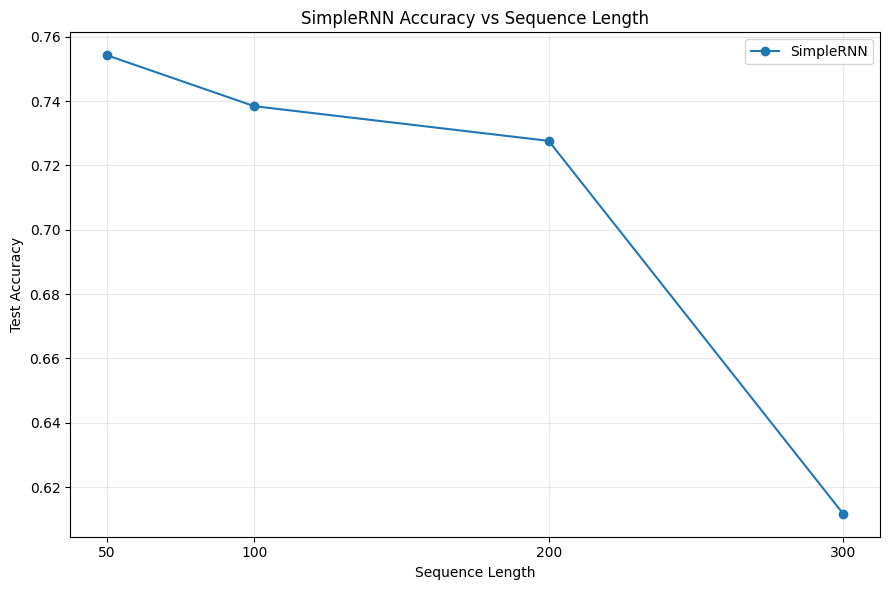

In [89]:
plt.figure(
    figsize=(9, 6)
)

plt.plot(
    sequence_lengths,
    sequence_accuracies,
    marker="o",
    label="SimpleRNN"
)

plt.title(
    "SimpleRNN Accuracy vs Sequence Length"
)

plt.xlabel(
    "Sequence Length"
)

plt.ylabel(
    "Test Accuracy"
)

plt.xticks(
    sequence_lengths
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "plots/accuracy_vs_sequence_length_rnn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Accuracy vs Sequence Length

Increasing sequence length provides the model with more words from each
review, but this does not guarantee better SimpleRNN performance.

A SimpleRNN has difficulty preserving useful information over many time
steps because of the vanishing-gradient problem.

As sequences become longer, additional words may therefore provide limited
benefit and can also introduce additional noise.

The observed test accuracies at sequence lengths 50, 100, 200 and 300
should be used to determine whether performance improved, plateaued or
declined in this experiment.

# Task 4.5 — Exploding Gradient Demo and Clipping
## Build High-Learning-Rate Model

In [90]:
tf.random.set_seed(42)

rnn_high_lr = Sequential([
    Input(
        shape=(MAXLEN,)
    ),

    Embedding(
        input_dim=10000,
        output_dim=32
    ),

    SimpleRNN(
        64
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

rnn_high_lr.compile(
    optimizer=Adam(
        learning_rate=0.05
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy"
    ]
)

rnn_high_lr.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

## Train Without Gradient Clipping

In [91]:
history_high_lr = rnn_high_lr.fit(
    X_train,
    y_train,

    epochs=5,

    batch_size=64,

    validation_split=0.1,

    verbose=1
)

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 73s 125ms/step - accuracy: 0.5336 - loss: 0.7066 - val_accuracy: 0.5362 - val_loss: 0.6834
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 69s 124ms/step - accuracy: 0.5341 - loss: nan - val_accuracy: 0.5021 - val_loss: nan
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 70s 126ms/step - accuracy: 0.4977 - loss: nan - val_accuracy: 0.5021 - val_loss: nan
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 70s 125ms/step - accuracy: 0.4977 - loss: nan - val_accuracy: 0.5021 - val_loss: nan
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 71s 127ms/step - accuracy: 0.4977 - loss: nan - val_accuracy: 0.5021 - val_loss: nan


## Build Same Model with clipnorm=1.0

In [92]:
tf.random.set_seed(42)

rnn_clipped = Sequential([
    Input(
        shape=(MAXLEN,)
    ),

    Embedding(
        input_dim=10000,
        output_dim=32
    ),

    SimpleRNN(
        64
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

rnn_clipped.compile(
    optimizer=Adam(
        learning_rate=0.05,
        clipnorm=1.0
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy"
    ]
)

rnn_clipped.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

## Train with Gradient Clipping

In [93]:
history_clipped = rnn_clipped.fit(
    X_train,
    y_train,

    epochs=5,

    batch_size=64,

    validation_split=0.1,

    verbose=1
)

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 77s 131ms/step - accuracy: 0.5141 - loss: 0.7297 - val_accuracy: 0.5268 - val_loss: 0.7357
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 71s 127ms/step - accuracy: 0.5426 - loss: 0.7132 - val_accuracy: 0.5281 - val_loss: 0.7842
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 71s 128ms/step - accuracy: 0.5651 - loss: 0.7010 - val_accuracy: 0.5364 - val_loss: 0.7413
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 66s 119ms/step - accuracy: 0.5779 - loss: 0.6881 - val_accuracy: 0.5465 - val_loss: 0.7336
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 71s 128ms/step - accuracy: 0.5890 - loss: 0.6797 - val_accuracy: 0.5581 - val_loss: 0.7275


## Compare Loss Curves

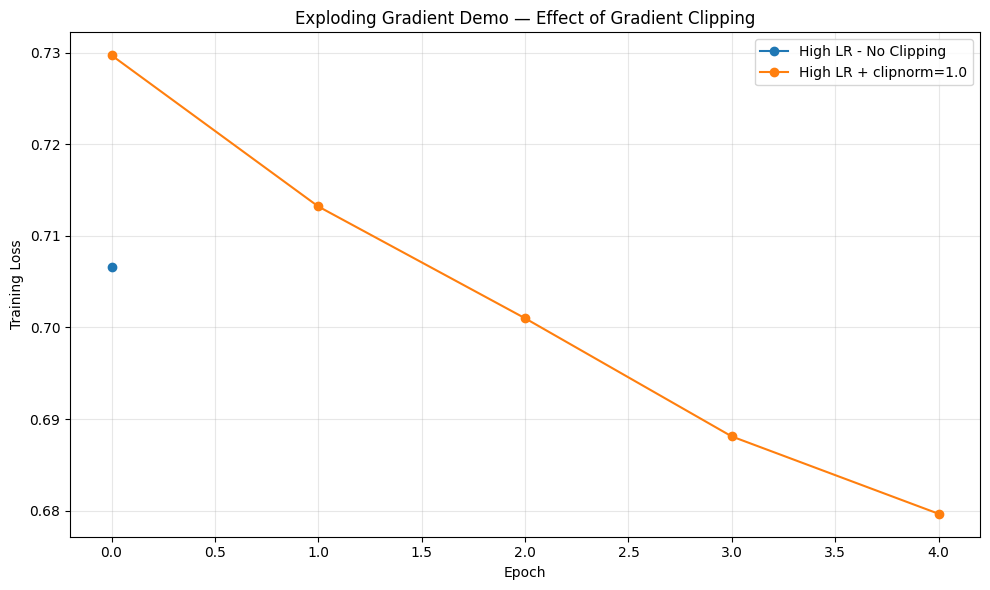

In [94]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_high_lr.history["loss"],
    marker="o",
    label="High LR - No Clipping"
)

plt.plot(
    history_clipped.history["loss"],
    marker="o",
    label="High LR + clipnorm=1.0"
)

plt.title(
    "Exploding Gradient Demo — Effect of Gradient Clipping"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Training Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "plots/gradient_clipping_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Compare Values

In [95]:
clipping_comparison = pd.DataFrame({
    "Epoch": range(
        1,
        len(history_high_lr.history["loss"]) + 1
    ),

    "No Clipping Loss":
        history_high_lr.history["loss"],

    "Clipnorm 1.0 Loss":
        history_clipped.history["loss"]
})

clipping_comparison

,Epoch,No Clipping Loss,Clipnorm 1.0 Loss
0,1,0.706612,0.729709
1,2,NaN,0.713206
2,3,NaN,0.701004
3,4,NaN,0.688105
4,5,NaN,0.679667


### Gradient Clipping

A deliberately large learning rate can make recurrent-network training
unstable because large gradients produce very large parameter updates.

Gradient clipping limits this problem.

With:

`clipnorm=1.0`

the optimizer rescales a gradient vector when its norm exceeds the
specified threshold.

This can prevent extremely large updates and make training more stable.

### Important Limitation

Gradient clipping addresses **exploding gradients**, but it does not solve
**vanishing gradients**.

If a gradient has already become extremely small, clipping does not make
it larger.

Therefore:

- Exploding gradient → Gradient clipping can help.
- Vanishing gradient → Gated architectures such as LSTM and GRU are needed.

The actual loss curves from this experiment should be used to describe
whether instability or spikes were observed.

# Task 4.6 — Problems Summary Table

# 4.6 Problems with SimpleRNN

| Problem | Cause | Symptom / Observation | Remedy |
|---|---|---|---|
| Vanishing gradient | Repeated multiplication by recurrent weights and activation derivatives smaller than 1 | Early information becomes difficult to learn across long sequences | LSTM / GRU gating |
| Exploding gradient | Repeated multiplication by factors larger than 1 | Unstable loss, large spikes or possibly NaN values | Gradient clipping |
| Slow sequential training | Time step `t` depends on the previous hidden state | RNN sequence processing is difficult to fully parallelize | Shorter sequences / GPU |
| Short-term memory | Useful information must pass through many recurrent transitions | Performance may plateau or decline as sequences become very long | LSTM / GRU gated memory |

# Task 4 Conclusion

SimpleRNN learns sequential information using **Backpropagation Through
Time (BPTT)**.

During BPTT, gradients are propagated backward through the recurrent
computation across many time steps.

Repeated multiplication can cause two major problems:

### 1. Vanishing Gradients

Gradients become extremely small, making it difficult for the network to
learn relationships between distant words.

### 2. Exploding Gradients

Gradients become extremely large, producing unstable parameter updates and
loss behaviour.

The sequence-length experiment investigates how SimpleRNN behaves as the
number of time steps increases.

The high-learning-rate experiment demonstrates training instability, while
`clipnorm=1.0` demonstrates a method for controlling excessively large
gradients.

However, clipping only addresses exploding gradients. It does not create
a reliable long-term memory path.

This limitation motivates the **Long Short-Term Memory (LSTM)** network
used in Task 5.

# Task 5: LSTM — Long Short-Term Memory

### Objective
Understand the architecture of Long Short-Term Memory (LSTM), its gates,
cell state and ability to preserve information across long sequences.

### Expected Output
- LSTM gate equations and explanation
- Explanation of how LSTM mitigates vanishing gradients
- LSTM parameter-count verification
- Manual NumPy LSTM implementation
- LSTM sentiment model
- Training and validation curves
- Complete evaluation metrics
- Gradient-flow comparison with SimpleRNN
- Stacked LSTM model

# Task 5.1 — LSTM Theory

## LSTM Architecture

## 5.1 LSTM Theory

A standard SimpleRNN can struggle to remember information across long
sequences because gradients may vanish during Backpropagation Through Time.

**Long Short-Term Memory (LSTM)** introduces a cell state and gates that
control how information is stored, removed and exposed.

An LSTM maintains:

- Hidden state \(h_t\)
- Cell state \(C_t\)

The cell state acts like a long-term memory path.

---

### 1. Forget Gate

\[
f_t = \sigma(W_f[h_{t-1},x_t] + b_f)
\]

The forget gate decides which information from the previous cell state
should be retained or forgotten.

Values close to:

- `1` → keep the information
- `0` → forget the information

---

### 2. Input Gate

\[
i_t = \sigma(W_i[h_{t-1},x_t] + b_i)
\]

The input gate decides how much new information should be written into
the cell state.

---

### 3. Candidate State

\[
g_t = \tanh(W_g[h_{t-1},x_t] + b_g)
\]

The candidate state contains new candidate information that may be added
to memory.

---

### 4. Cell-State Update

\[
C_t = f_t * C_{t-1} + i_t * g_t
\]

The new cell state combines:

1. Information retained from the previous memory.
2. New information selected by the input gate.

The cell state is often described as a **conveyor belt** that allows
information to travel through many time steps with relatively small
changes.

---

### 5. Output Gate

\[
o_t = \sigma(W_o[h_{t-1},x_t] + b_o)
\]

The output gate decides how much of the cell-state information should be
revealed as the current hidden state.

---

### 6. Hidden State

\[
h_t = o_t * \tanh(C_t)
\]

The hidden state represents the information exposed by the LSTM at the
current time step.

---

### LSTM Gates in Simple Words

| Component | Purpose |
|---|---|
| Forget Gate | What old information should I forget? |
| Input Gate | What new information should I write? |
| Candidate State | What new information could be stored? |
| Cell State | Long-term memory |
| Output Gate | What information should I reveal? |
| Hidden State | Current output / short-term representation |

# Task 5.2 — Why LSTM Helps Vanishing Gradients

## 5.2 Why LSTM Helps with Vanishing Gradients

In a SimpleRNN, information and gradients repeatedly pass through a
recurrent weight matrix and the derivative of `tanh`.

Over many time steps, repeated multiplication by values smaller than one
can cause the gradient to become extremely small.

LSTM introduces a separate cell state:

\[
C_t = f_tC_{t-1} + i_tg_t
\]

The important difference is that the cell state uses an **additive update**
and element-wise multiplication.

Along the cell-state path:

\[
\frac{\partial C_t}{\partial C_{t-1}} = f_t
\]

When the forget gate \(f_t\) remains close to 1, gradients can pass through
many time steps without rapidly shrinking.

Therefore, LSTM provides a more direct path for both information and
gradients.

This allows an LSTM to learn longer-range dependencies more effectively
than a standard SimpleRNN.

# Task 5.3 — LSTM Parameter Count
## Calculate Parameters

In [96]:
units = 64
embedding_dim = 32

lstm_formula_params = (
    4
    * units
    * (embedding_dim + units + 1)
)

print("LSTM Parameter Formula:")
print(
    f"4 × {units} × "
    f"({embedding_dim} + {units} + 1)"
)

print("\nTotal LSTM Parameters:")
print(lstm_formula_params)

LSTM Parameter Formula:
4 × 64 × (32 + 64 + 1)

Total LSTM Parameters:
24832


## Breakdown

In [97]:
single_gate_params = (
    units
    * (embedding_dim + units + 1)
)

print(
    "Parameters for one gate:",
    single_gate_params
)

print(
    "Number of LSTM components:",
    4
)

print(
    "Total:",
    4 * single_gate_params
)

Parameters for one gate: 6208
Number of LSTM components: 4
Total: 24832


## Verify Against Keras

In [98]:
lstm_parameter_model = Sequential([
    Input(shape=(MAXLEN,)),

    Embedding(
        input_dim=10000,
        output_dim=32
    ),

    LSTM(64),

    Dense(
        1,
        activation="sigmoid"
    )
])

lstm_parameter_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

## Extract LSTM Parameters

In [99]:
keras_lstm_params = (
    lstm_parameter_model
    .layers[1]
    .count_params()
)

print(
    "Formula Parameters:",
    lstm_formula_params
)

print(
    "Keras LSTM Parameters:",
    keras_lstm_params
)

print(
    "Counts Match:",
    lstm_formula_params == keras_lstm_params
)

Formula Parameters: 24832
Keras LSTM Parameters: 24832
Counts Match: True


### Why does LSTM have four times the SimpleRNN parameter count?

A SimpleRNN has one recurrent transformation.

An LSTM contains four major transformations:

1. Forget gate
2. Input gate
3. Candidate state
4. Output gate

Each requires its own input weights, recurrent weights and bias.

Therefore:

\[
LSTM\ Parameters
=
4 \times SimpleRNN\ Parameters
\]

For 64 units and a 32-dimensional input:

\[
4 \times 6208 = 24832
\]

# Task 5.4 — Manual Single-Step LSTM in NumPy
## Sigmoid Function

In [100]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

## Initialize Manual LSTM

In [101]:
np.random.seed(42)

input_size = 2
hidden_size = 3
sequence_length = 4

# Combined previous hidden state + current input
combined_size = hidden_size + input_size

# Forget gate
Wf = np.random.randn(
    hidden_size,
    combined_size
) * 0.5

bf = np.random.randn(
    hidden_size
) * 0.5

# Input gate
Wi = np.random.randn(
    hidden_size,
    combined_size
) * 0.5

bi = np.random.randn(
    hidden_size
) * 0.5

# Candidate state
Wg = np.random.randn(
    hidden_size,
    combined_size
) * 0.5

bg = np.random.randn(
    hidden_size
) * 0.5

# Output gate
Wo = np.random.randn(
    hidden_size,
    combined_size
) * 0.5

bo = np.random.randn(
    hidden_size
) * 0.5

print("Wf:", Wf.shape)
print("Wi:", Wi.shape)
print("Wg:", Wg.shape)
print("Wo:", Wo.shape)

Wf: (3, 5)
Wi: (3, 5)
Wg: (3, 5)
Wo: (3, 5)


## Create Four-Step Input

In [102]:
lstm_sequence = np.random.randn(
    sequence_length,
    input_size
)

print(
    "Input Sequence Shape:",
    lstm_sequence.shape
)

print("\nInput Sequence:")
print(lstm_sequence)

Input Sequence Shape: (4, 2)

Input Sequence:
[[-0.03582604  1.56464366]
 [-2.6197451   0.8219025 ]
 [ 0.08704707 -0.29900735]
 [ 0.09176078 -1.98756891]]


## Manual LSTM Forward Pass

In [103]:
h_prev = np.zeros(hidden_size)
C_prev = np.zeros(hidden_size)

manual_lstm_results = []

for t in range(sequence_length):

    x_t = lstm_sequence[t]

    # Combine previous hidden state and current input
    combined = np.concatenate([
        h_prev,
        x_t
    ])

    # Forget gate
    f_t = sigmoid(
        Wf @ combined + bf
    )

    # Input gate
    i_t = sigmoid(
        Wi @ combined + bi
    )

    # Candidate state
    g_t = np.tanh(
        Wg @ combined + bg
    )

    # Update cell state
    C_t = (
        f_t * C_prev
        + i_t * g_t
    )

    # Output gate
    o_t = sigmoid(
        Wo @ combined + bo
    )

    # Hidden state
    h_t = (
        o_t * np.tanh(C_t)
    )

    manual_lstm_results.append({
        "Time Step": t + 1,
        "Forget Gate": f_t.copy(),
        "Input Gate": i_t.copy(),
        "Output Gate": o_t.copy(),
        "Cell State": C_t.copy(),
        "Hidden State": h_t.copy()
    })

    print(
        "\n" + "=" * 70
    )

    print(
        f"TIME STEP {t + 1}"
    )

    print("=" * 70)

    print(
        "Forget Gate f(t):",
        np.round(f_t, 4)
    )

    print(
        "Input Gate i(t):",
        np.round(i_t, 4)
    )

    print(
        "Output Gate o(t):",
        np.round(o_t, 4)
    )

    print(
        "Cell State C(t):",
        np.round(C_t, 4)
    )

    print(
        "Hidden State h(t):",
        np.round(h_t, 4)
    )

    h_prev = h_t
    C_prev = C_t


TIME STEP 1
Forget Gate f(t): [0.3795 0.4816 0.239 ]
Input Gate i(t): [0.3841 0.6739 0.3421]
Output Gate o(t): [0.4855 0.324  0.7377]
Cell State C(t): [ 0.1399 -0.4744  0.1815]
Hidden State h(t): [ 0.0675 -0.1431  0.1324]

TIME STEP 2
Forget Gate f(t): [0.0909 0.565  0.8795]
Input Gate i(t): [0.4905 0.8881 0.0439]
Output Gate o(t): [0.5327 0.7673 0.3843]
Cell State C(t): [-0.0301  0.4965  0.2031]
Hidden State h(t): [-0.016   0.3525  0.077 ]

TIME STEP 3
Forget Gate f(t): [0.4543 0.426  0.5653]
Input Gate i(t): [0.3243 0.556  0.3549]
Output Gate o(t): [0.4349 0.5528 0.7288]
Cell State C(t): [-0.2082  0.0351  0.2447]
Hidden State h(t): [-0.0892  0.0194  0.1749]

TIME STEP 4
Forget Gate f(t): [0.5136 0.274  0.8607]
Input Gate i(t): [0.389  0.5133 0.368 ]
Output Gate o(t): [0.3151 0.778  0.605 ]
Cell State C(t): [-0.4128  0.1468  0.1973]
Hidden State h(t): [-0.1232  0.1134  0.1178]


## Display as Small Table

In [104]:
manual_lstm_table = []

for result in manual_lstm_results:

    manual_lstm_table.append({
        "Time Step": result["Time Step"],

        "f Mean":
            np.mean(result["Forget Gate"]),

        "i Mean":
            np.mean(result["Input Gate"]),

        "o Mean":
            np.mean(result["Output Gate"]),

        "C Mean":
            np.mean(result["Cell State"]),

        "h Mean":
            np.mean(result["Hidden State"])
    })

manual_lstm_df = pd.DataFrame(
    manual_lstm_table
)

manual_lstm_df

,Time Step,f Mean,i Mean,o Mean,C Mean,h Mean
0,1,0.366719,0.466695,0.515751,-0.051008,0.018923
1,2,0.511805,0.474173,0.561456,0.223147,0.137802
2,3,0.481866,0.411731,0.572142,0.023903,0.035017
3,4,0.549445,0.423445,0.566050,-0.022906,0.036030


# Memory Preservation

### Manual LSTM Observation

The forget gate controls how much of the previous cell state is preserved,
while the input gate controls how much new candidate information is added.

From:

\[
C_t = f_tC_{t-1} + i_tg_t
\]

if:

\[
f_t \approx 1
\]

and:

\[
i_t \approx 0
\]

then:

\[
C_t \approx C_{t-1}
\]

Therefore, the previous memory is preserved almost unchanged.

This is one of the key mechanisms that allows LSTM networks to maintain
information over longer sequences.

# Task 5.5 — Build, Train and Evaluate LSTM
## Build LSTM

In [105]:
tf.random.set_seed(42)

lstm_model = build_model(
    cell_type="lstm",
    units=64
)

lstm_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

## Verify LSTM Layer Parameters Again

In [106]:
print(
    "LSTM Layer Parameters:",
    lstm_model.layers[1].count_params()
)

print(
    "Expected:",
    24832
)

LSTM Layer Parameters: 24832
Expected: 24832


## Create Callbacks

In [107]:
early_stopping_lstm = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

time_callback_lstm = TimeHistory()

## Train LSTM

In [108]:
lstm_history = lstm_model.fit(
    X_train,
    y_train,

    epochs=15,

    batch_size=64,

    validation_split=0.1,

    callbacks=[
        early_stopping_lstm,
        time_callback_lstm
    ],

    verbose=1
)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step - accuracy: 0.7890 - loss: 0.4374Epoch 1 Time: 168.21 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 168s 297ms/step - accuracy: 0.7890 - loss: 0.4374 - val_accuracy: 0.8611 - val_loss: 0.3361
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step - accuracy: 0.8866 - loss: 0.2850Epoch 2 Time: 175.60 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 176s 315ms/step - accuracy: 0.8866 - loss: 0.2850 - val_accuracy: 0.8762 - val_loss: 0.3336
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.9165 - loss: 0.2243Epoch 3 Time: 184.50 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 185s 330ms/step - accuracy: 0.9165 - loss: 0.2243 - val_accuracy: 0.8805 - val_loss: 0.3412
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.9268 - loss: 0.1984Epoch 4 Time: 175.80 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 176s 315ms/step - accuracy: 0.9268 - loss: 0.1984 - val_accuracy: 0.8848 - val_loss: 0.3065
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/ste

## LSTM Training Information

In [109]:
lstm_epochs_trained = len(
    lstm_history.history["loss"]
)

lstm_avg_time = np.mean(
    time_callback_lstm.times
)

print(
    "Epochs Trained:",
    lstm_epochs_trained
)

print(
    f"Average Time per Epoch: "
    f"{lstm_avg_time:.2f} seconds"
)

print("\nEpoch Times:")

for i, epoch_time in enumerate(
    time_callback_lstm.times,
    start=1
):

    print(
        f"Epoch {i}: "
        f"{epoch_time:.2f} seconds"
    )

Epochs Trained: 7
Average Time per Epoch: 179.99 seconds

Epoch Times:
Epoch 1: 168.21 seconds
Epoch 2: 175.60 seconds
Epoch 3: 184.50 seconds
Epoch 4: 175.80 seconds
Epoch 5: 177.39 seconds
Epoch 6: 179.60 seconds
Epoch 7: 198.79 seconds


## LSTM Training Curves

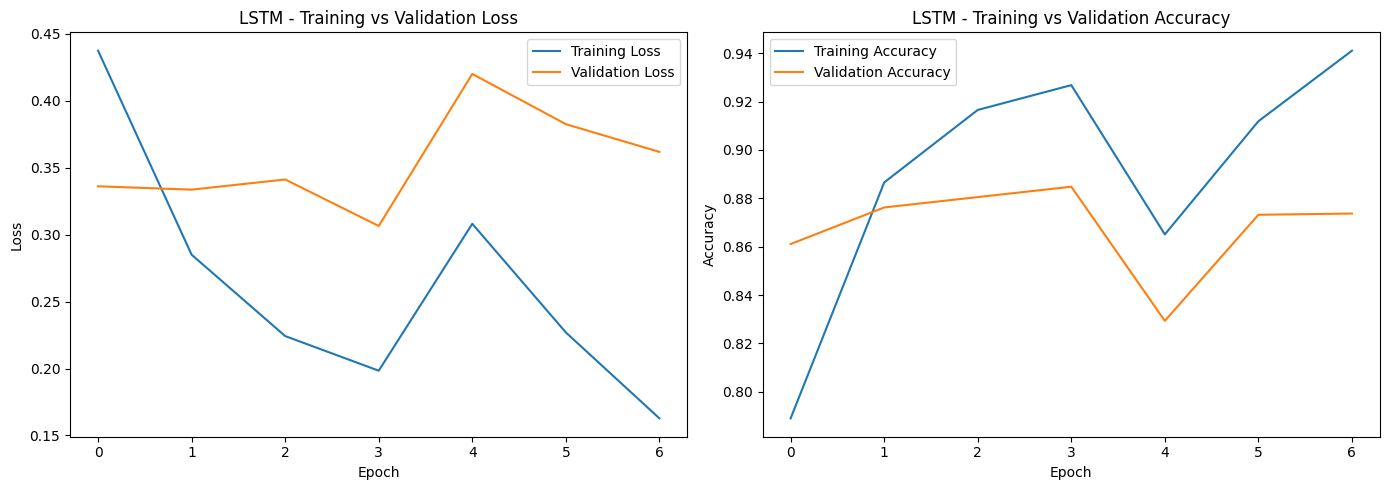

In [110]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Loss
axes[0].plot(
    lstm_history.history["loss"],
    label="Training Loss"
)

axes[0].plot(
    lstm_history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "LSTM - Training vs Validation Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()


# Accuracy
axes[1].plot(
    lstm_history.history["accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    lstm_history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title(
    "LSTM - Training vs Validation Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    "plots/training_curves_lstm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Test Accuracy

In [111]:
lstm_test_loss, lstm_test_accuracy = (
    lstm_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )
)

print(
    f"LSTM Test Loss: "
    f"{lstm_test_loss:.4f}"
)

print(
    f"LSTM Test Accuracy: "
    f"{lstm_test_accuracy:.4f}"
)

LSTM Test Loss: 0.3058
LSTM Test Accuracy: 0.8868


## Predictions

In [112]:
lstm_prob = lstm_model.predict(
    X_test,
    verbose=0
).ravel()

lstm_pred = (
    lstm_prob >= 0.5
).astype(int)

print(
    "First 10 probabilities:"
)

print(
    lstm_prob[:10]
)

print(
    "\nFirst 10 predictions:"
)

print(
    lstm_pred[:10]
)

First 10 probabilities:
[0.00479243 0.9899792  0.8868683  0.02790447 0.01781242 0.9902553
 0.08963675 0.20930372 0.9972415  0.0192504 ]

First 10 predictions:
[0 1 1 0 0 1 0 0 1 0]


## Classification Report

In [113]:
print(
    classification_report(
        y_test,
        lstm_pred,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

    Negative     0.9037    0.8648    0.8838      4940
    Positive     0.8713    0.9086    0.8895      4977

    accuracy                         0.8868      9917
   macro avg     0.8875    0.8867    0.8867      9917
weighted avg     0.8875    0.8868    0.8867      9917



## Metrics

In [114]:
lstm_precision = precision_score(
    y_test,
    lstm_pred,
    zero_division=0
)

lstm_recall = recall_score(
    y_test,
    lstm_pred,
    zero_division=0
)

lstm_f1 = f1_score(
    y_test,
    lstm_pred,
    zero_division=0
)

lstm_auc = roc_auc_score(
    y_test,
    lstm_prob
)

print(
    f"Accuracy  : {lstm_test_accuracy:.4f}"
)

print(
    f"Precision : {lstm_precision:.4f}"
)

print(
    f"Recall    : {lstm_recall:.4f}"
)

print(
    f"F1 Score  : {lstm_f1:.4f}"
)

print(
    f"ROC-AUC   : {lstm_auc:.4f}"
)

Accuracy  : 0.8868
Precision : 0.8713
Recall    : 0.9086
F1 Score  : 0.8895
ROC-AUC   : 0.9497


## Confusion Matrix

In [115]:
lstm_cm = confusion_matrix(
    y_test,
    lstm_pred
)

print(
    "LSTM Confusion Matrix:"
)

print(lstm_cm)

LSTM Confusion Matrix:
[[4272  668]
 [ 455 4522]]


## Confusion Matrix Heatmap

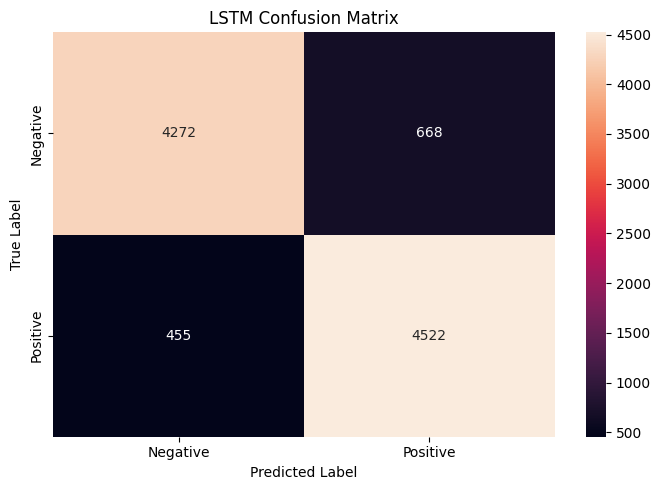

In [116]:
plt.figure(
    figsize=(7, 5)
)

sns.heatmap(
    lstm_cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Negative",
        "Positive"
    ],
    yticklabels=[
        "Negative",
        "Positive"
    ]
)

plt.title(
    "LSTM Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.tight_layout()

plt.savefig(
    "plots/confusion_matrix_lstm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## ROC Curve

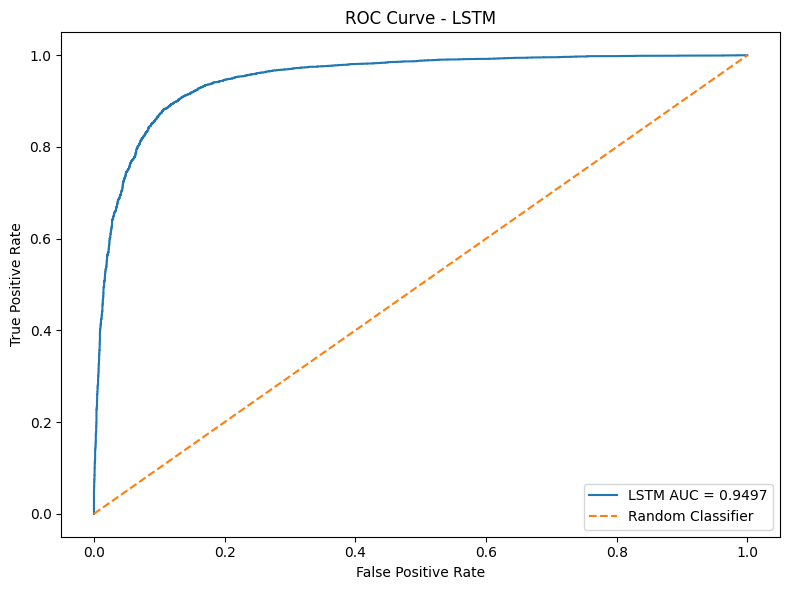

In [117]:
lstm_fpr, lstm_tpr, lstm_thresholds = (
    roc_curve(
        y_test,
        lstm_prob
    )
)

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    lstm_fpr,
    lstm_tpr,
    label=f"LSTM AUC = {lstm_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "ROC Curve - LSTM"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()

plt.tight_layout()

plt.show()

## Store LSTM Results

In [118]:
results["LSTM"] = {

    "Parameters":
        lstm_model.count_params(),

    "Time per Epoch (s)":
        lstm_avg_time,

    "Epochs Trained":
        lstm_epochs_trained,

    "Test Accuracy":
        lstm_test_accuracy,

    "Precision":
        lstm_precision,

    "Recall":
        lstm_recall,

    "F1":
        lstm_f1,

    "ROC-AUC":
        lstm_auc
}

results["LSTM"]

{'Parameters': 344897,
 'Time per Epoch (s)': 179.98583613123213,
 'Epochs Trained': 7,
 'Test Accuracy': 0.8867601156234741,
 'Precision': 0.8712909441233141,
 'Recall': 0.9085794655414908,
 'F1': 0.889544605094915,
 'ROC-AUC': 0.9496914551877911}

## Current Comparison

In [119]:
pd.DataFrame(
    results
).T

,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
ANN Baseline,1548929.0,12.599379,5.0,0.866189,0.866319,0.867189,0.866754,0.937937
SimpleRNN,326273.0,68.883499,4.0,0.790057,0.886929,0.666667,0.761184,0.878709
LSTM,344897.0,179.985836,7.0,0.886760,0.871291,0.908579,0.889545,0.949691


# Task 5.6 — Gradient Flow Comparison
## Create LSTM Gradient Layers

In [120]:
embedding_grad_lstm = Embedding(
    input_dim=10000,
    output_dim=32
)

lstm_grad_layer = LSTM(
    64,
    return_sequences=True
)

dense_grad_lstm = Dense(
    1,
    activation="sigmoid"
)

## LSTM GradientTape

In [121]:
with tf.GradientTape() as tape:

    embedded_lstm = embedding_grad_lstm(
        X_gradient_batch
    )

    H_lstm = lstm_grad_layer(
        embedded_lstm
    )

    tape.watch(H_lstm)

    last_lstm_state = (
        H_lstm[:, -1, :]
    )

    lstm_gradient_prediction = (
        dense_grad_lstm(
            last_lstm_state
        )
    )

    lstm_gradient_prediction = tf.squeeze(
        lstm_gradient_prediction,
        axis=-1
    )

    lstm_gradient_loss = (
        tf.keras.losses.binary_crossentropy(
            y_gradient_batch,
            lstm_gradient_prediction
        )
    )

    lstm_gradient_loss = (
        tf.reduce_mean(
            lstm_gradient_loss
        )
    )


grads_lstm = tape.gradient(
    lstm_gradient_loss,
    H_lstm
)

print(
    "Hidden State Shape:",
    H_lstm.shape
)

print(
    "Gradient Shape:",
    grads_lstm.shape
)

Hidden State Shape: (64, 600, 64)
Gradient Shape: (64, 600, 64)


## LSTM Gradient Norms

In [122]:
lstm_gradient_norms = tf.norm(
    grads_lstm,
    axis=-1
)

lstm_gradient_norms = tf.reduce_mean(
    lstm_gradient_norms,
    axis=0
)

lstm_gradient_norms = (
    lstm_gradient_norms.numpy()
)

print(
    "LSTM Gradient Norm Shape:",
    lstm_gradient_norms.shape
)

print(
    "\nFirst Time Step:",
    lstm_gradient_norms[0]
)

print(
    "Final Time Step:",
    lstm_gradient_norms[-1]
)

LSTM Gradient Norm Shape: (600,)

First Time Step: 0.0
Final Time Step: 0.0099819815


## SimpleRNN vs LSTM Gradient Plot

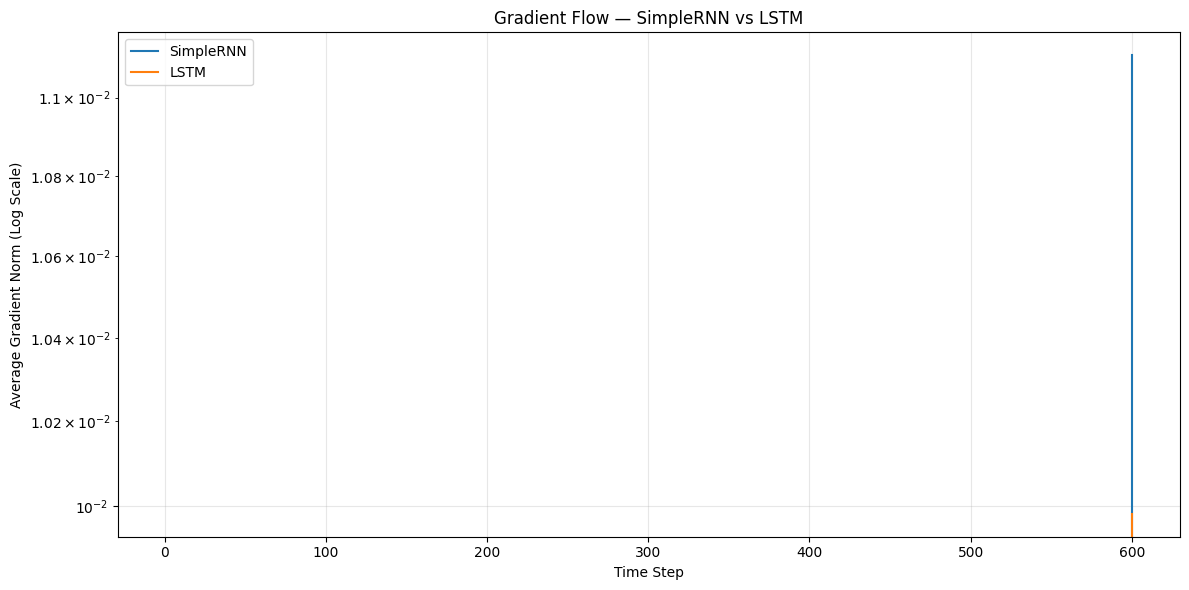

In [123]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    np.arange(1, MAXLEN + 1),
    rnn_gradient_norms,
    label="SimpleRNN"
)

plt.plot(
    np.arange(1, MAXLEN + 1),
    lstm_gradient_norms,
    label="LSTM"
)

plt.yscale("log")

plt.title(
    "Gradient Flow — SimpleRNN vs LSTM"
)

plt.xlabel(
    "Time Step"
)

plt.ylabel(
    "Average Gradient Norm (Log Scale)"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "plots/gradient_norm_rnn_vs_lstm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Quantitative Comparison

In [124]:
print(
    "EARLIEST TIME STEP"
)

print(
    "SimpleRNN:",
    rnn_gradient_norms[0]
)

print(
    "LSTM:",
    lstm_gradient_norms[0]
)

if rnn_gradient_norms[0] > 0:

    ratio = (
        lstm_gradient_norms[0]
        /
        rnn_gradient_norms[0]
    )

    print(
        "\nLSTM / SimpleRNN Ratio:",
        ratio
    )

else:

    print(
        "\nSimpleRNN earliest gradient is zero, "
        "so a finite ratio cannot be calculated."
    )

EARLIEST TIME STEP
SimpleRNN: 0.0
LSTM: 0.0

SimpleRNN earliest gradient is zero, so a finite ratio cannot be calculated.


### SimpleRNN vs LSTM Gradient Flow

The gradient-flow experiment compares the gradient norm across sequence
positions for SimpleRNN and LSTM.

LSTM was designed to preserve information and gradients through its gated
cell-state path.

Its cell-state update is:

\[
C_t=f_tC_{t-1}+i_tg_t
\]

When the forget gate remains close to one, information can persist through
many time steps.

The quantitative values printed above should be used to describe the
actual difference observed in this notebook.

The tensor-gradient experiment should not be used to claim a numerical
improvement that is not visible in the measured results.

# Task 5.7 — Stacked LSTM

## 5.7 Stacked LSTM

A stacked LSTM contains multiple LSTM layers.

The first LSTM must use:

`return_sequences=True`

because the second LSTM expects a complete sequence as its input.

Without `return_sequences=True`, the first LSTM would return only its final
hidden state, giving the second LSTM a single vector rather than a sequence.

Architecture:

`Embedding → LSTM(64, return_sequences=True) → LSTM(32) → Dense(1)`

## Build Stacked LSTM

In [125]:
tf.random.set_seed(42)

stacked_lstm_model = Sequential([
    Input(
        shape=(MAXLEN,)
    ),

    Embedding(
        input_dim=10000,
        output_dim=32
    ),

    LSTM(
        64,
        return_sequences=True
    ),

    LSTM(
        32
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

stacked_lstm_model.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy"
    ]
)

stacked_lstm_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 600, 64)        │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,281 (1.36 MB)

 Trainable params: 357,281 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

## Callbacks

In [126]:
early_stopping_stacked = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

time_callback_stacked = TimeHistory()

## Train Stacked LSTM

In [127]:
stacked_lstm_history = (
    stacked_lstm_model.fit(
        X_train,
        y_train,

        epochs=15,

        batch_size=64,

        validation_split=0.1,

        callbacks=[
            early_stopping_stacked,
            time_callback_stacked
        ],

        verbose=1
    )
)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.8041 - loss: 0.4272Epoch 1 Time: 304.29 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 304s 535ms/step - accuracy: 0.8041 - loss: 0.4272 - val_accuracy: 0.8046 - val_loss: 0.4689
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 502ms/step - accuracy: 0.8663 - loss: 0.3206Epoch 2 Time: 290.25 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 290s 520ms/step - accuracy: 0.8663 - loss: 0.3206 - val_accuracy: 0.8808 - val_loss: 0.3114
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 502ms/step - accuracy: 0.8958 - loss: 0.2696Epoch 3 Time: 290.40 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 290s 521ms/step - accuracy: 0.8958 - loss: 0.2696 - val_accuracy: 0.8848 - val_loss: 0.2955
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 558ms/step - accuracy: 0.9113 - loss: 0.2315Epoch 4 Time: 319.79 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 320s 573ms/step - accuracy: 0.9113 - loss: 0.2315 - val_accuracy: 0.8777 - val_loss: 0.3197
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step 

## Training Information

In [128]:
stacked_epochs_trained = len(
    stacked_lstm_history.history["loss"]
)

stacked_avg_time = np.mean(
    time_callback_stacked.times
)

print(
    "Epochs Trained:",
    stacked_epochs_trained
)

print(
    f"Average Time per Epoch: "
    f"{stacked_avg_time:.2f} seconds"
)

print(
    "Total Parameters:",
    stacked_lstm_model.count_params()
)

Epochs Trained: 6
Average Time per Epoch: 1358.36 seconds
Total Parameters: 357281


## Stacked LSTM Curves

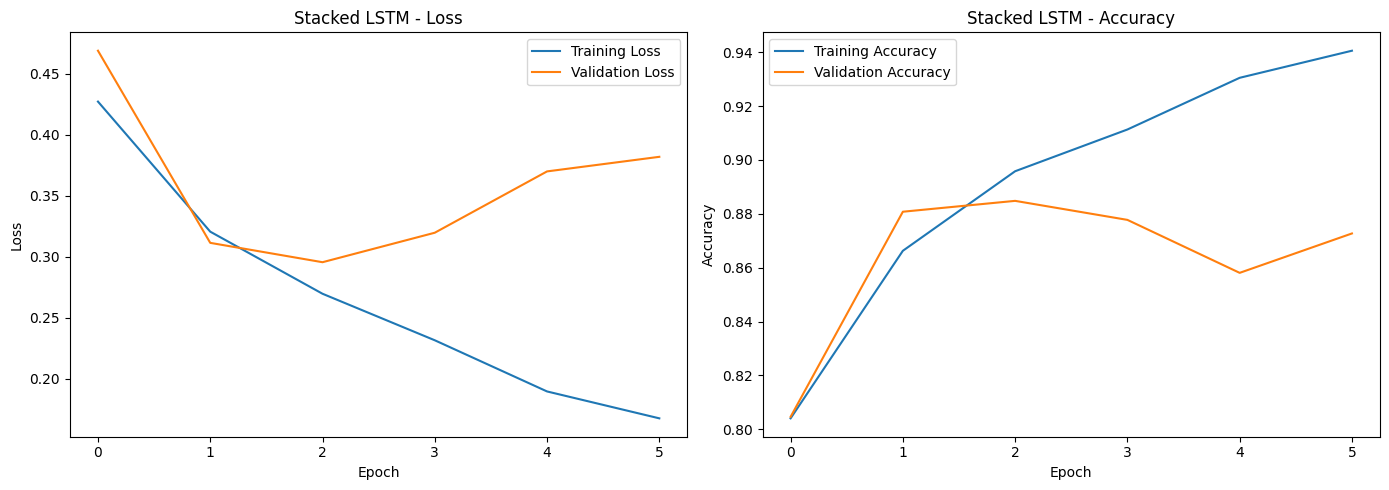

In [129]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    stacked_lstm_history.history["loss"],
    label="Training Loss"
)

axes[0].plot(
    stacked_lstm_history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "Stacked LSTM - Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()


axes[1].plot(
    stacked_lstm_history.history["accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    stacked_lstm_history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title(
    "Stacked LSTM - Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()

plt.show()

## Test Evaluation

In [130]:
stacked_test_loss, stacked_test_accuracy = (
    stacked_lstm_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )
)

print(
    f"Stacked LSTM Test Loss: "
    f"{stacked_test_loss:.4f}"
)

print(
    f"Stacked LSTM Test Accuracy: "
    f"{stacked_test_accuracy:.4f}"
)

Stacked LSTM Test Loss: 0.2944
Stacked LSTM Test Accuracy: 0.8831


## Predictions and Metrics

In [131]:
stacked_prob = stacked_lstm_model.predict(
    X_test,
    verbose=0
).ravel()

stacked_pred = (
    stacked_prob >= 0.5
).astype(int)


stacked_precision = precision_score(
    y_test,
    stacked_pred,
    zero_division=0
)

stacked_recall = recall_score(
    y_test,
    stacked_pred,
    zero_division=0
)

stacked_f1 = f1_score(
    y_test,
    stacked_pred,
    zero_division=0
)

stacked_auc = roc_auc_score(
    y_test,
    stacked_prob
)


print(
    f"Accuracy  : {stacked_test_accuracy:.4f}"
)

print(
    f"Precision : {stacked_precision:.4f}"
)

print(
    f"Recall    : {stacked_recall:.4f}"
)

print(
    f"F1 Score  : {stacked_f1:.4f}"
)

print(
    f"ROC-AUC   : {stacked_auc:.4f}"
)

Accuracy  : 0.8831
Precision : 0.8858
Recall    : 0.8807
F1 Score  : 0.8832
ROC-AUC   : 0.9499


## Classification Report

In [132]:
print(
    classification_report(
        y_test,
        stacked_pred,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

    Negative     0.8805    0.8856    0.8830      4940
    Positive     0.8858    0.8807    0.8832      4977

    accuracy                         0.8831      9917
   macro avg     0.8831    0.8831    0.8831      9917
weighted avg     0.8831    0.8831    0.8831      9917



## Confusion Matrix

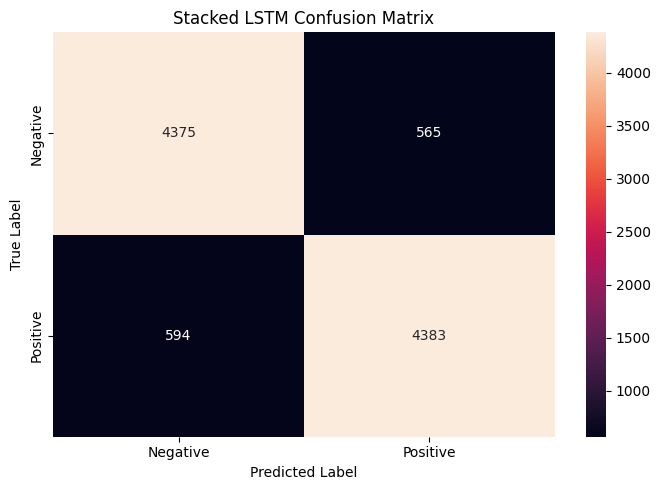

In [133]:
stacked_cm = confusion_matrix(
    y_test,
    stacked_pred
)

plt.figure(
    figsize=(7, 5)
)

sns.heatmap(
    stacked_cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Negative",
        "Positive"
    ],
    yticklabels=[
        "Negative",
        "Positive"
    ]
)

plt.title(
    "Stacked LSTM Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.tight_layout()

plt.show()

## Store Results

In [134]:
results["Stacked LSTM"] = {

    "Parameters":
        stacked_lstm_model.count_params(),

    "Time per Epoch (s)":
        stacked_avg_time,

    "Epochs Trained":
        stacked_epochs_trained,

    "Test Accuracy":
        stacked_test_accuracy,

    "Precision":
        stacked_precision,

    "Recall":
        stacked_recall,

    "F1":
        stacked_f1,

    "ROC-AUC":
        stacked_auc
}

results["Stacked LSTM"]

{'Parameters': 357281,
 'Time per Epoch (s)': 1358.3558209339778,
 'Epochs Trained': 6,
 'Test Accuracy': 0.8831299543380737,
 'Precision': 0.8858124494745352,
 'Recall': 0.8806509945750453,
 'F1': 0.8832241813602015,
 'ROC-AUC': 0.9498931928978566}

## Compare Current Models

In [135]:
current_results = pd.DataFrame(
    results
).T

current_results

,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
ANN Baseline,1548929.0,12.599379,5.0,0.866189,0.866319,0.867189,0.866754,0.937937
SimpleRNN,326273.0,68.883499,4.0,0.790057,0.886929,0.666667,0.761184,0.878709
LSTM,344897.0,179.985836,7.0,0.886760,0.871291,0.908579,0.889545,0.949691
Stacked LSTM,357281.0,1358.355821,6.0,0.883130,0.885812,0.880651,0.883224,0.949893


## Compare LSTM vs Stacked LSTM

In [136]:
lstm_comparison = pd.DataFrame({

    "Model": [
        "LSTM",
        "Stacked LSTM"
    ],

    "Parameters": [
        lstm_model.count_params(),
        stacked_lstm_model.count_params()
    ],

    "Test Accuracy": [
        lstm_test_accuracy,
        stacked_test_accuracy
    ],

    "F1": [
        lstm_f1,
        stacked_f1
    ],

    "ROC-AUC": [
        lstm_auc,
        stacked_auc
    ],

    "Time/Epoch": [
        lstm_avg_time,
        stacked_avg_time
    ]
})

lstm_comparison

,Model,Parameters,Test Accuracy,F1,ROC-AUC,Time/Epoch
0,LSTM,344897,0.88676,0.889545,0.949691,179.985836
1,Stacked LSTM,357281,0.88313,0.883224,0.949893,1358.355821


### Stacked LSTM Analysis

The stacked LSTM adds additional recurrent depth.

This gives the network more capacity to learn complex sequential
representations, but it also increases:

- Number of parameters
- Training time
- Computational cost
- Potential risk of overfitting

The first LSTM uses `return_sequences=True` because the second LSTM requires
the complete sequence of hidden states as its input.

Whether the additional depth improves this IMDB sentiment-classification
task should be determined from the actual test accuracy, F1, ROC-AUC and
training-time results printed above.

# Task 5 Conclusion

Long Short-Term Memory improves on SimpleRNN by introducing a separate
cell state and gating mechanisms.

The three gates have different responsibilities:

- **Forget gate:** controls what old information is retained.
- **Input gate:** controls what new information is written.
- **Output gate:** controls what information is exposed.

The cell-state update provides a more direct path for information and
gradients across long sequences.

For 64 hidden units and a 32-dimensional embedding, the LSTM recurrent
layer contains:

\[
4 \times 64 \times (32+64+1)=24,832
\]

parameters.

A manual NumPy LSTM was implemented over four time steps to demonstrate
the forget, input and output gates, cell state and hidden state.

The LSTM sentiment classifier was then trained using the same setup as
SimpleRNN to allow a fair comparison.

Finally, a stacked LSTM was implemented using:

`LSTM(64, return_sequences=True) → LSTM(32)`

to investigate whether additional recurrent depth improves performance
enough to justify its additional parameters and training cost.

# Task 6: GRU — Gated Recurrent Unit

### Objective
Understand the GRU architecture and compare it with SimpleRNN and LSTM
for sentiment classification.

### Expected Output
- GRU equations and gate explanation
- GRU vs LSTM comparison
- GRU parameter-count verification
- GRU sentiment model
- Training and validation curves
- Complete evaluation metrics
- SimpleRNN vs LSTM vs GRU gradient comparison
- Hidden-unit sensitivity experiment for 32, 64 and 128 units

# Task 6.1 — GRU Theory

## GRU Equations

## 6.1 GRU Theory

A **Gated Recurrent Unit (GRU)** is a gated recurrent architecture designed
to improve the ability of an RNN to learn long-term dependencies.

GRU is simpler than LSTM because it does not maintain a separate cell state.

It mainly uses two gates:

1. Update Gate
2. Reset Gate

---

### 1. Update Gate

\[
z_t = \sigma(W_z[h_{t-1},x_t] + b_z)
\]

The update gate determines how much new candidate information should be
used and how much previous hidden-state information should be retained.

---

### 2. Reset Gate

\[
r_t = \sigma(W_r[h_{t-1},x_t] + b_r)
\]

The reset gate controls how much of the previous hidden state should be
used when calculating the new candidate hidden state.

---

### 3. Candidate Hidden State

\[
\tilde{h}_t =
\tanh(W_h[r_t * h_{t-1},x_t] + b_h)
\]

The reset gate is applied to the previous hidden state before calculating
the candidate representation.

---

### 4. Final Hidden State

\[
h_t =
(1-z_t) * h_{t-1}
+
z_t * \tilde{h}_t
\]

The update gate controls the balance between the previous hidden state and
the new candidate hidden state.

---

### GRU in Simple Words

| Component | Purpose |
|---|---|
| Update Gate | Controls old vs new information |
| Reset Gate | Controls how much previous information is used |
| Candidate Hidden State | Creates new candidate information |
| Hidden State | Stores the current memory/output |

Unlike LSTM, GRU does not have a separate cell state \(C_t\).

# Task 6.2 — GRU vs LSTM

## 6.2 GRU vs LSTM

| Feature | LSTM | GRU |
|---|---|---|
| Main gates | Forget, Input and Output gates | Update and Reset gates |
| Separate cell state | Yes | No |
| Hidden state | Yes | Yes |
| Architecture | More complex | Simpler |
| Parameter count | Higher | Lower |
| Training speed | Usually slower | Usually faster |
| Long-term dependencies | Designed to handle them | Designed to handle them |
| Memory control | Separate cell state and hidden state | Hidden state acts as memory |
| Typical choice | Useful when more explicit memory control is beneficial | Useful when simpler/faster gated recurrence is preferred |

### How GRU Combines LSTM Ideas

LSTM separately controls forgetting and writing new information.

GRU uses the update gate to control the balance between old hidden-state
information and new candidate information.

Therefore, GRU provides a simpler gated architecture while still addressing
some of the long-term dependency problems of a standard SimpleRNN.

# Task 6.3 — GRU Parameter Count
## Manual Parameter Calculation

In [137]:
gru_units = 64
gru_input_dim = 32

gru_formula_params = 3 * (
    (gru_units * gru_input_dim)
    + (gru_units * gru_units)
    + (2 * gru_units)
)

print("GRU Parameter Calculation")
print("-------------------------")

print(
    f"3 × ({gru_units} × {gru_input_dim}"
    f" + {gru_units} × {gru_units}"
    f" + 2 × {gru_units})"
)

print("\nGRU Parameters:")
print(gru_formula_params)

GRU Parameter Calculation
-------------------------
3 × (64 × 32 + 64 × 64 + 2 × 64)

GRU Parameters:
18816


## Verify with Keras

In [138]:
gru_parameter_model = Sequential([
    Input(shape=(MAXLEN,)),

    Embedding(
        input_dim=10000,
        output_dim=32
    ),

    GRU(
        64,
        reset_after=True
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

gru_parameter_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

## Compare Formula with Keras

In [139]:
keras_gru_params = (
    gru_parameter_model
    .layers[1]
    .count_params()
)

print(
    "Formula Parameters:",
    gru_formula_params
)

print(
    "Keras Parameters:",
    keras_gru_params
)

print(
    "Counts Match:",
    gru_formula_params == keras_gru_params
)

Formula Parameters: 18816
Keras Parameters: 18816
Counts Match: True


# Task 6.4 — Build and Train GRU
## Build GRU Model

In [140]:
tf.random.set_seed(42)

gru_model = build_model(
    cell_type="gru",
    units=64
)

gru_model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

## Create GRU Callbacks

In [141]:
early_stopping_gru = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

time_callback_gru = TimeHistory()

## Train GRU

In [142]:
gru_history = gru_model.fit(
    X_train,
    y_train,

    epochs=15,

    batch_size=64,

    validation_split=0.1,

    callbacks=[
        early_stopping_gru,
        time_callback_gru
    ],

    verbose=1
)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.7927 - loss: 0.4335Epoch 1 Time: 173.38 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 173s 307ms/step - accuracy: 0.7927 - loss: 0.4335 - val_accuracy: 0.8780 - val_loss: 0.3020
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step - accuracy: 0.8995 - loss: 0.2563Epoch 2 Time: 169.74 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 170s 304ms/step - accuracy: 0.8995 - loss: 0.2563 - val_accuracy: 0.8896 - val_loss: 0.2939
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.9263 - loss: 0.1975Epoch 3 Time: 174.53 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 175s 313ms/step - accuracy: 0.9263 - loss: 0.1975 - val_accuracy: 0.8929 - val_loss: 0.2692
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.9445 - loss: 0.1566Epoch 4 Time: 168.33 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 168s 302ms/step - accuracy: 0.9445 - loss: 0.1566 - val_accuracy: 0.8876 - val_loss: 0.3227
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/ste

## Training Information

In [143]:
gru_epochs_trained = len(
    gru_history.history["loss"]
)

gru_avg_time = np.mean(
    time_callback_gru.times
)

print(
    "Epochs Trained:",
    gru_epochs_trained
)

print(
    f"Average Time per Epoch: "
    f"{gru_avg_time:.2f} seconds"
)

print("\nIndividual Epoch Times:")

for i, epoch_time in enumerate(
    time_callback_gru.times,
    start=1
):
    print(
        f"Epoch {i}: "
        f"{epoch_time:.2f} seconds"
    )

Epochs Trained: 6
Average Time per Epoch: 174.53 seconds

Individual Epoch Times:
Epoch 1: 173.38 seconds
Epoch 2: 169.74 seconds
Epoch 3: 174.53 seconds
Epoch 4: 168.33 seconds
Epoch 5: 186.84 seconds
Epoch 6: 174.35 seconds


## GRU Training Curves

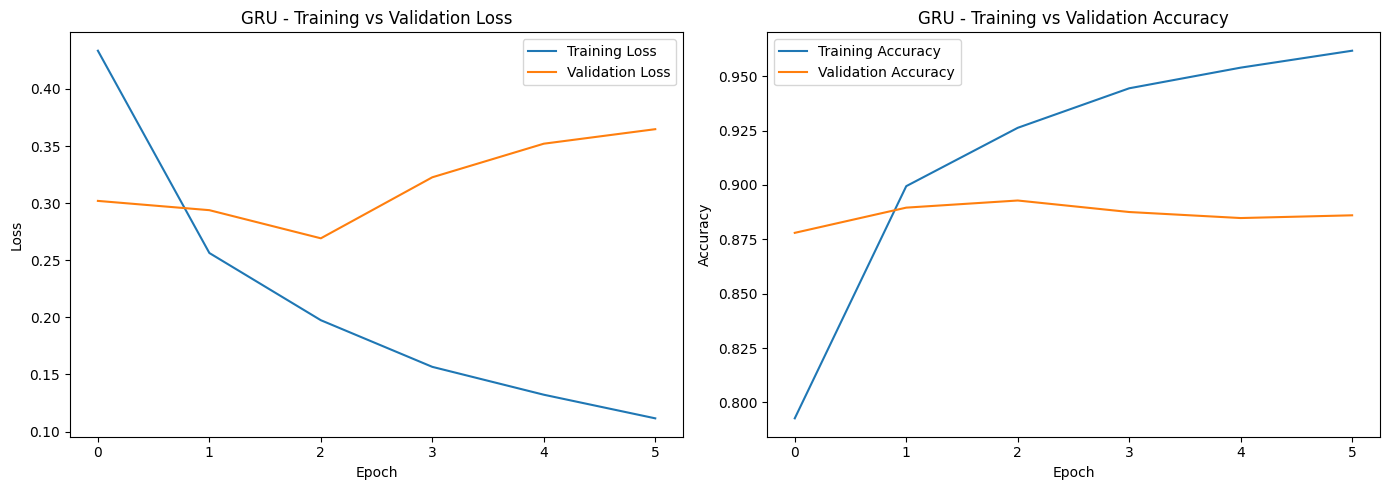

In [144]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Loss
axes[0].plot(
    gru_history.history["loss"],
    label="Training Loss"
)

axes[0].plot(
    gru_history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "GRU - Training vs Validation Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()


# Accuracy
axes[1].plot(
    gru_history.history["accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    gru_history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title(
    "GRU - Training vs Validation Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    "plots/training_curves_gru.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Test Evaluation

In [145]:
gru_test_loss, gru_test_accuracy = (
    gru_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )
)

print(
    f"GRU Test Loss: "
    f"{gru_test_loss:.4f}"
)

print(
    f"GRU Test Accuracy: "
    f"{gru_test_accuracy:.4f}"
)

GRU Test Loss: 0.2694
GRU Test Accuracy: 0.8973


## Predictions

In [146]:
gru_prob = gru_model.predict(
    X_test,
    verbose=0
).ravel()

gru_pred = (
    gru_prob >= 0.5
).astype(int)

print(
    "First 10 probabilities:"
)

print(gru_prob[:10])

print(
    "\nFirst 10 predictions:"
)

print(gru_pred[:10])

First 10 probabilities:
[0.00417241 0.98651004 0.8920068  0.03736494 0.01418276 0.99621874
 0.06780558 0.03199701 0.99631375 0.01061522]

First 10 predictions:
[0 1 1 0 0 1 0 0 1 0]


## Classification Report

In [147]:
print(
    classification_report(
        y_test,
        gru_pred,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

    Negative     0.8978    0.8960    0.8969      4940
    Positive     0.8969    0.8987    0.8978      4977

    accuracy                         0.8973      9917
   macro avg     0.8974    0.8973    0.8973      9917
weighted avg     0.8973    0.8973    0.8973      9917



## Calculate Metrics

In [148]:
gru_precision = precision_score(
    y_test,
    gru_pred,
    zero_division=0
)

gru_recall = recall_score(
    y_test,
    gru_pred,
    zero_division=0
)

gru_f1 = f1_score(
    y_test,
    gru_pred,
    zero_division=0
)

gru_auc = roc_auc_score(
    y_test,
    gru_prob
)

print(
    f"Accuracy  : {gru_test_accuracy:.4f}"
)

print(
    f"Precision : {gru_precision:.4f}"
)

print(
    f"Recall    : {gru_recall:.4f}"
)

print(
    f"F1 Score  : {gru_f1:.4f}"
)

print(
    f"ROC-AUC   : {gru_auc:.4f}"
)

Accuracy  : 0.8973
Precision : 0.8969
Recall    : 0.8987
F1 Score  : 0.8978
ROC-AUC   : 0.9595


## Confusion Matrix

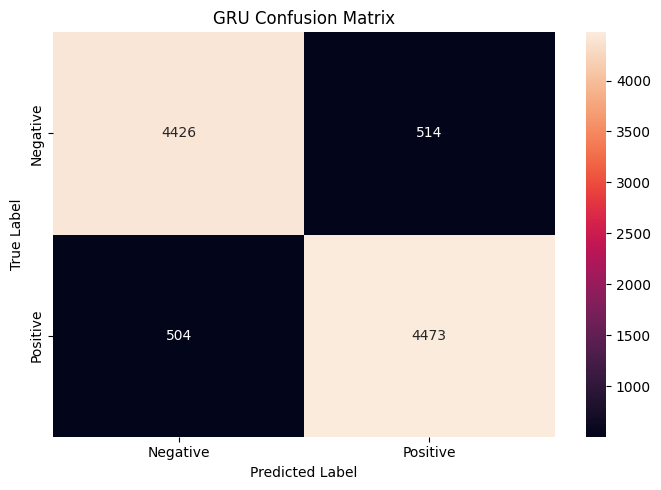

In [149]:
gru_cm = confusion_matrix(
    y_test,
    gru_pred
)

plt.figure(
    figsize=(7, 5)
)

sns.heatmap(
    gru_cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Negative",
        "Positive"
    ],
    yticklabels=[
        "Negative",
        "Positive"
    ]
)

plt.title(
    "GRU Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.tight_layout()

plt.savefig(
    "plots/confusion_matrix_gru.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## ROC Curve

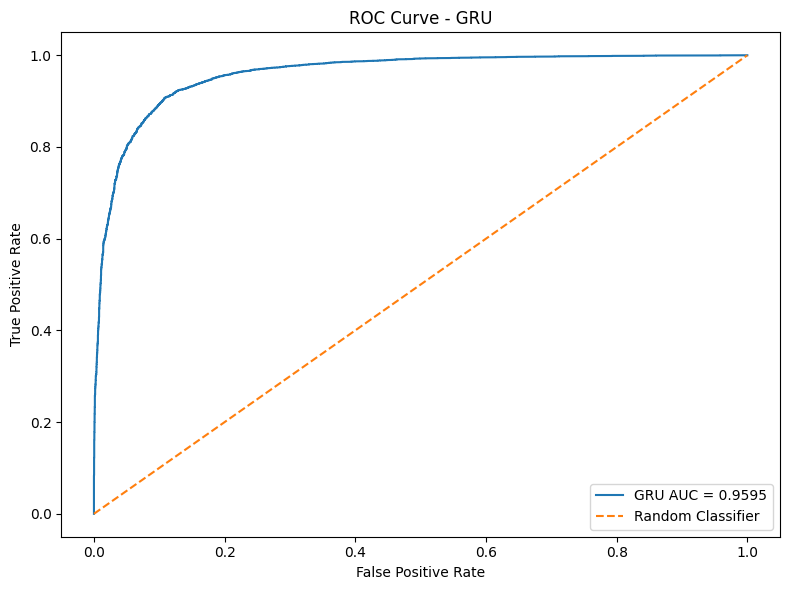

In [150]:
gru_fpr, gru_tpr, gru_thresholds = (
    roc_curve(
        y_test,
        gru_prob
    )
)

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    gru_fpr,
    gru_tpr,
    label=f"GRU AUC = {gru_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "ROC Curve - GRU"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()

plt.tight_layout()
plt.show()

## Store GRU Results

In [151]:
results["GRU"] = {

    "Parameters":
        gru_model.count_params(),

    "Time per Epoch (s)":
        gru_avg_time,

    "Epochs Trained":
        gru_epochs_trained,

    "Test Accuracy":
        gru_test_accuracy,

    "Precision":
        gru_precision,

    "Recall":
        gru_recall,

    "F1":
        gru_f1,

    "ROC-AUC":
        gru_auc
}

results["GRU"]

{'Parameters': 338881,
 'Time per Epoch (s)': 174.5266811052958,
 'Epochs Trained': 6,
 'Test Accuracy': 0.8973479866981506,
 'Precision': 0.8969320232604773,
 'Recall': 0.8987341772151899,
 'F1': 0.897832195905259,
 'ROC-AUC': 0.9594859226937842}

## Current Model Comparison

In [152]:
current_results = pd.DataFrame(
    results
).T

current_results

,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
ANN Baseline,1548929.0,12.599379,5.0,0.866189,0.866319,0.867189,0.866754,0.937937
SimpleRNN,326273.0,68.883499,4.0,0.790057,0.886929,0.666667,0.761184,0.878709
LSTM,344897.0,179.985836,7.0,0.886760,0.871291,0.908579,0.889545,0.949691
Stacked LSTM,357281.0,1358.355821,6.0,0.883130,0.885812,0.880651,0.883224,0.949893
GRU,338881.0,174.526681,6.0,0.897348,0.896932,0.898734,0.897832,0.959486


# Task 6.5 — Gradient Comparison: RNN vs LSTM vs GRU
## Create GRU Gradient Layers

In [153]:
embedding_grad_gru = Embedding(
    input_dim=10000,
    output_dim=32
)

gru_grad_layer = GRU(
    64,
    return_sequences=True
)

dense_grad_gru = Dense(
    1,
    activation="sigmoid"
)

## GRU GradientTape

In [154]:
with tf.GradientTape() as tape:

    embedded_gru = embedding_grad_gru(
        X_gradient_batch
    )

    H_gru = gru_grad_layer(
        embedded_gru
    )

    tape.watch(H_gru)

    last_gru_state = (
        H_gru[:, -1, :]
    )

    gru_gradient_prediction = (
        dense_grad_gru(
            last_gru_state
        )
    )

    gru_gradient_prediction = tf.squeeze(
        gru_gradient_prediction,
        axis=-1
    )

    gru_gradient_loss = (
        tf.keras.losses.binary_crossentropy(
            y_gradient_batch,
            gru_gradient_prediction
        )
    )

    gru_gradient_loss = tf.reduce_mean(
        gru_gradient_loss
    )


grads_gru = tape.gradient(
    gru_gradient_loss,
    H_gru
)

print(
    "GRU Hidden States:",
    H_gru.shape
)

print(
    "GRU Gradients:",
    grads_gru.shape
)

GRU Hidden States: (64, 600, 64)
GRU Gradients: (64, 600, 64)


## Calculate GRU Gradient Norms

In [155]:
gru_gradient_norms = tf.norm(
    grads_gru,
    axis=-1
)

gru_gradient_norms = tf.reduce_mean(
    gru_gradient_norms,
    axis=0
)

gru_gradient_norms = (
    gru_gradient_norms.numpy()
)

print(
    "Gradient Norm Shape:",
    gru_gradient_norms.shape
)

print(
    "First Time Step:",
    gru_gradient_norms[0]
)

print(
    "Final Time Step:",
    gru_gradient_norms[-1]
)

Gradient Norm Shape: (600,)
First Time Step: 0.0
Final Time Step: 0.010779635


## All Three Gradient Curves

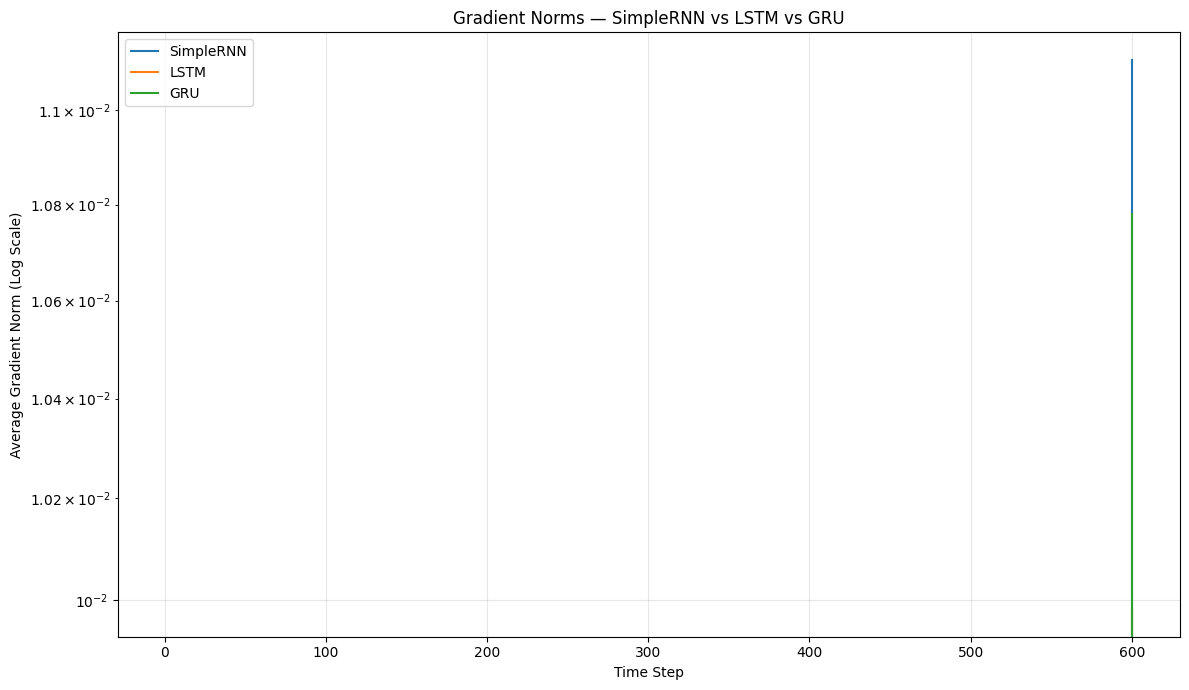

In [156]:
plt.figure(
    figsize=(12, 7)
)

time_axis = np.arange(
    1,
    MAXLEN + 1
)

plt.plot(
    time_axis,
    rnn_gradient_norms,
    label="SimpleRNN"
)

plt.plot(
    time_axis,
    lstm_gradient_norms,
    label="LSTM"
)

plt.plot(
    time_axis,
    gru_gradient_norms,
    label="GRU"
)

plt.yscale("log")

plt.title(
    "Gradient Norms — SimpleRNN vs LSTM vs GRU"
)

plt.xlabel(
    "Time Step"
)

plt.ylabel(
    "Average Gradient Norm (Log Scale)"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "plots/gradient_norms_all_cells.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Compare Early Gradient Values

In [157]:
gradient_comparison = pd.DataFrame({

    "Model": [
        "SimpleRNN",
        "LSTM",
        "GRU"
    ],

    "First Time Step": [
        rnn_gradient_norms[0],
        lstm_gradient_norms[0],
        gru_gradient_norms[0]
    ],

    "Middle Time Step": [
        rnn_gradient_norms[
            len(rnn_gradient_norms) // 2
        ],

        lstm_gradient_norms[
            len(lstm_gradient_norms) // 2
        ],

        gru_gradient_norms[
            len(gru_gradient_norms) // 2
        ]
    ],

    "Final Time Step": [
        rnn_gradient_norms[-1],
        lstm_gradient_norms[-1],
        gru_gradient_norms[-1]
    ]
})

gradient_comparison

,Model,First Time Step,Middle Time Step,Final Time Step
0,SimpleRNN,0.0,0.0,0.011109
1,LSTM,0.0,0.0,0.009982
2,GRU,0.0,0.0,0.010780


### Gradient Flow Comparison

SimpleRNN, LSTM and GRU were compared using the same gradient-analysis
approach.

SimpleRNN uses a basic recurrent hidden state, whereas LSTM and GRU use
gating mechanisms designed to preserve useful information over longer
sequences.

The plotted and tabulated gradient values above should be used to rank
the three models for this experiment.

The ranking should be based on the actual measured gradient norms rather
than assuming beforehand that one architecture must always produce a
larger value.

# Task 6.6 — Hidden-Unit Sensitivity
## Experiment Setup

In [158]:
unit_sizes = [
    32,
    64,
    128
]

sensitivity_results = []

print(
    "Hidden-unit sizes:",
    unit_sizes
)

Hidden-unit sizes: [32, 64, 128]


## Train LSTM Models

In [159]:
for units in unit_sizes:

    print(
        "\n" + "=" * 70
    )

    print(
        f"LSTM - {units} Units"
    )

    print(
        "=" * 70
    )

    np.random.seed(42)
    tf.random.set_seed(42)

    sensitivity_model = build_model(
        cell_type="lstm",
        units=units
    )

    sensitivity_model.fit(
        X_train,
        y_train,

        epochs=6,

        batch_size=64,

        validation_split=0.1,

        verbose=1
    )

    test_loss, test_accuracy = (
        sensitivity_model.evaluate(
            X_test,
            y_test,
            verbose=0
        )
    )

    sensitivity_results.append({
        "Cell Type": "LSTM",
        "Units": units,
        "Parameters":
            sensitivity_model.count_params(),
        "Test Accuracy":
            test_accuracy
    })

    print(
        f"\nLSTM {units} Units"
    )

    print(
        "Parameters:",
        sensitivity_model.count_params()
    )

    print(
        f"Test Accuracy: "
        f"{test_accuracy:.4f}"
    )

    del sensitivity_model

    tf.keras.backend.clear_session()


LSTM - 32 Units
Epoch 1/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 96s 165ms/step - accuracy: 0.8102 - loss: 0.4093 - val_accuracy: 0.8573 - val_loss: 0.3464
Epoch 2/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 98s 176ms/step - accuracy: 0.8994 - loss: 0.2587 - val_accuracy: 0.8903 - val_loss: 0.2784
Epoch 3/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 90s 162ms/step - accuracy: 0.9162 - loss: 0.2204 - val_accuracy: 0.8888 - val_loss: 0.2919
Epoch 4/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 91s 163ms/step - accuracy: 0.9222 - loss: 0.2053 - val_accuracy: 0.8825 - val_loss: 0.3075
Epoch 5/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 93s 167ms/step - accuracy: 0.9264 - loss: 0.1954 - val_accuracy: 0.8765 - val_loss: 0.3218
Epoch 6/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 95s 170ms/step - accuracy: 0.9381 - loss: 0.1668 - val_accuracy: 0.8619 - val_loss: 0.3742

LSTM 32 Units
Parameters: 328353
Test Accuracy: 0.8686

LSTM - 64 Units
Epoch 1/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 142s 252ms/step - accuracy: 0.7867 - loss: 0.4491 - val_accuracy: 0.8472 - val_loss: 0.3572

## Train GRU Models

In [160]:
for units in unit_sizes:

    print(
        "\n" + "=" * 70
    )

    print(
        f"GRU - {units} Units"
    )

    print(
        "=" * 70
    )

    np.random.seed(42)
    tf.random.set_seed(42)

    sensitivity_model = build_model(
        cell_type="gru",
        units=units
    )

    sensitivity_model.fit(
        X_train,
        y_train,

        epochs=6,

        batch_size=64,

        validation_split=0.1,

        verbose=1
    )

    test_loss, test_accuracy = (
        sensitivity_model.evaluate(
            X_test,
            y_test,
            verbose=0
        )
    )

    sensitivity_results.append({
        "Cell Type": "GRU",
        "Units": units,
        "Parameters":
            sensitivity_model.count_params(),
        "Test Accuracy":
            test_accuracy
    })

    print(
        f"\nGRU {units} Units"
    )

    print(
        "Parameters:",
        sensitivity_model.count_params()
    )

    print(
        f"Test Accuracy: "
        f"{test_accuracy:.4f}"
    )

    del sensitivity_model

    tf.keras.backend.clear_session()


GRU - 32 Units
Epoch 1/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 118s 207ms/step - accuracy: 0.7854 - loss: 0.4463 - val_accuracy: 0.8563 - val_loss: 0.3414
Epoch 2/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 111s 199ms/step - accuracy: 0.8842 - loss: 0.2876 - val_accuracy: 0.8518 - val_loss: 0.3586
Epoch 3/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 530s 952ms/step - accuracy: 0.9083 - loss: 0.2384 - val_accuracy: 0.8775 - val_loss: 0.3941
Epoch 4/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 107s 193ms/step - accuracy: 0.9337 - loss: 0.1828 - val_accuracy: 0.8820 - val_loss: 0.3373
Epoch 5/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 2816s 5s/step - accuracy: 0.9443 - loss: 0.1581 - val_accuracy: 0.8845 - val_loss: 0.3088
Epoch 6/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 220s 393ms/step - accuracy: 0.9506 - loss: 0.1399 - val_accuracy: 0.8787 - val_loss: 0.3338

GRU 32 Units
Parameters: 326369
Test Accuracy: 0.8813

GRU - 64 Units
Epoch 1/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 161s 283ms/step - accuracy: 0.8000 - loss: 0.4205 - val_accuracy: 0.8596 - val_loss: 0.336

## Results DataFrame


In [161]:
sensitivity_df = pd.DataFrame(
    sensitivity_results
)

sensitivity_df

,Cell Type,Units,Parameters,Test Accuracy
0,LSTM,32,328353,0.868609
1,LSTM,64,344897,0.873450
2,LSTM,128,402561,0.862761
3,GRU,32,326369,0.881315
4,GRU,64,338881,0.875567
5,GRU,128,382337,0.888474


## Separate LSTM and GRU Results

In [162]:
lstm_sensitivity = sensitivity_df[
    sensitivity_df["Cell Type"] == "LSTM"
]

gru_sensitivity = sensitivity_df[
    sensitivity_df["Cell Type"] == "GRU"
]

display(
    lstm_sensitivity
)

display(
    gru_sensitivity
)

,Cell Type,Units,Parameters,Test Accuracy
0,LSTM,32,328353,0.868609
1,LSTM,64,344897,0.873450
2,LSTM,128,402561,0.862761


,Cell Type,Units,Parameters,Test Accuracy
3,GRU,32,326369,0.881315
4,GRU,64,338881,0.875567
5,GRU,128,382337,0.888474


## Test Accuracy vs Units

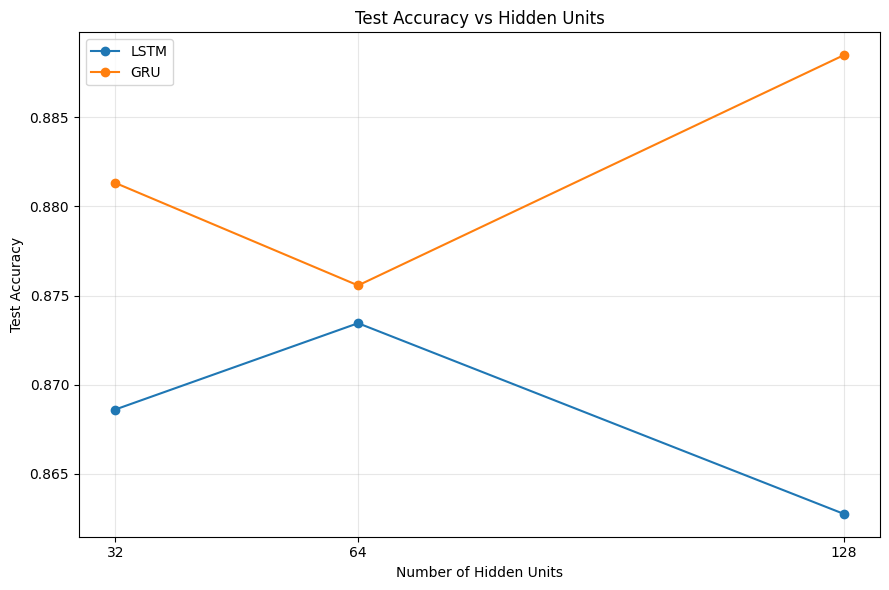

In [163]:
plt.figure(
    figsize=(9, 6)
)

plt.plot(
    lstm_sensitivity["Units"],
    lstm_sensitivity["Test Accuracy"],
    marker="o",
    label="LSTM"
)

plt.plot(
    gru_sensitivity["Units"],
    gru_sensitivity["Test Accuracy"],
    marker="o",
    label="GRU"
)

plt.title(
    "Test Accuracy vs Hidden Units"
)

plt.xlabel(
    "Number of Hidden Units"
)

plt.ylabel(
    "Test Accuracy"
)

plt.xticks(
    unit_sizes
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "plots/accuracy_vs_hidden_units.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Parameter Count vs Units

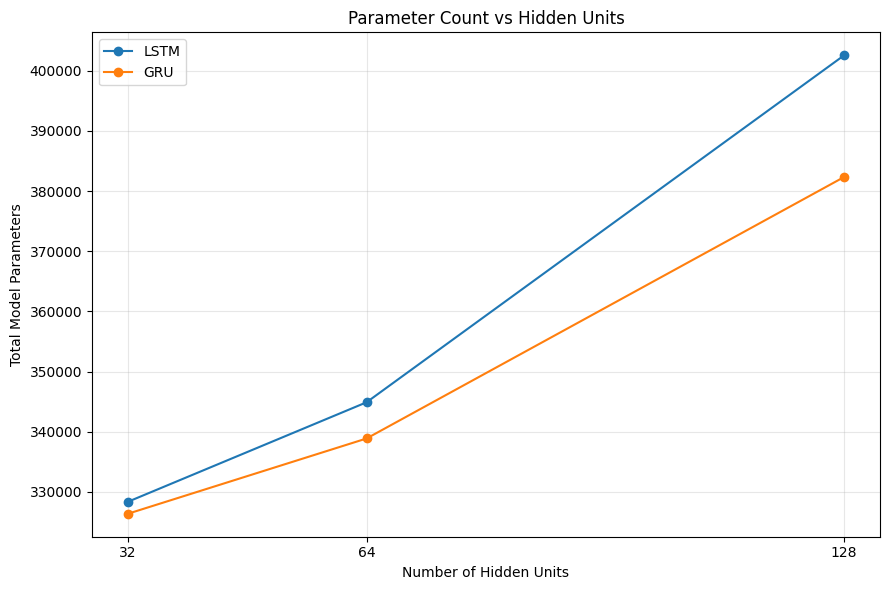

In [164]:
plt.figure(
    figsize=(9, 6)
)

plt.plot(
    lstm_sensitivity["Units"],
    lstm_sensitivity["Parameters"],
    marker="o",
    label="LSTM"
)

plt.plot(
    gru_sensitivity["Units"],
    gru_sensitivity["Parameters"],
    marker="o",
    label="GRU"
)

plt.title(
    "Parameter Count vs Hidden Units"
)

plt.xlabel(
    "Number of Hidden Units"
)

plt.ylabel(
    "Total Model Parameters"
)

plt.xticks(
    unit_sizes
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "plots/parameters_vs_hidden_units.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Find Best Sensitivity Result

In [165]:
best_sensitivity = sensitivity_df.loc[
    sensitivity_df[
        "Test Accuracy"
    ].idxmax()
]

print(
    "Best Configuration:"
)

print(
    best_sensitivity
)

Best Configuration:
Cell Type             GRU
Units                 128
Parameters         382337
Test Accuracy    0.888474
Name: 5, dtype: object


### Hidden-Unit Sensitivity Analysis

Increasing the number of hidden units increases the capacity of both LSTM
and GRU.

More hidden units allow the model to learn more complex representations,
but they also increase:

- Parameter count
- Memory usage
- Training time
- Risk of overfitting

The experiment compares 32, 64 and 128 hidden units for both architectures.

The best configuration should be selected from the actual test-accuracy
results rather than assuming that the largest model is automatically best.

A production model should balance predictive performance against model
size and computational cost.

# Task 6 Conclusion

GRU is a gated recurrent architecture that uses an **update gate** and
**reset gate**.

Unlike LSTM, GRU does not maintain a separate cell state. This makes its
architecture simpler and generally gives it fewer parameters.

For 64 units and an embedding dimension of 32, the Keras GRU recurrent
layer contains:

\[
18,816
\]

parameters, compared with:

\[
24,832
\]

for the corresponding LSTM recurrent layer.

The GRU sentiment classifier was trained and evaluated using the same
experimental setup as SimpleRNN and LSTM.

Gradient-flow experiments were also performed for all three recurrent
architectures.

Finally, LSTM and GRU models with 32, 64 and 128 hidden units were trained
to investigate the relationship between model capacity, parameter count
and test accuracy.

The final model choice should be based on the complete experimental
results rather than accuracy alone.

# Task 7: Final Comparison & Inference

### Objective
Compare all trained models, analyze their strengths and weaknesses,
inspect classification errors, and create a reusable sentiment-prediction
function.

### Models Compared
1. ANN Baseline
2. SimpleRNN
3. LSTM
4. Stacked LSTM
5. GRU

### Expected Output
- Complete model-comparison table
- Combined ROC curves
- Accuracy by review length
- Misclassified-review analysis
- Reusable `predict_sentiment()` function
- Six custom review predictions
- Final production recommendation

# Task 7.1 — Final Results Table
## Create Results DataFrame

In [166]:
results_df = pd.DataFrame(
    results
).T.reset_index()

results_df = results_df.rename(
    columns={
        "index": "Model"
    }
)

results_df

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN Baseline,1548929.0,12.599379,5.0,0.866189,0.866319,0.867189,0.866754,0.937937
1,SimpleRNN,326273.0,68.883499,4.0,0.790057,0.886929,0.666667,0.761184,0.878709
2,LSTM,344897.0,179.985836,7.0,0.886760,0.871291,0.908579,0.889545,0.949691
3,Stacked LSTM,357281.0,1358.355821,6.0,0.883130,0.885812,0.880651,0.883224,0.949893
4,GRU,338881.0,174.526681,6.0,0.897348,0.896932,0.898734,0.897832,0.959486


## Arrange Columns

In [167]:
results_df = results_df[
    [
        "Model",
        "Parameters",
        "Time per Epoch (s)",
        "Epochs Trained",
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
]

results_df

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN Baseline,1548929.0,12.599379,5.0,0.866189,0.866319,0.867189,0.866754,0.937937
1,SimpleRNN,326273.0,68.883499,4.0,0.790057,0.886929,0.666667,0.761184,0.878709
2,LSTM,344897.0,179.985836,7.0,0.886760,0.871291,0.908579,0.889545,0.949691
3,Stacked LSTM,357281.0,1358.355821,6.0,0.883130,0.885812,0.880651,0.883224,0.949893
4,GRU,338881.0,174.526681,6.0,0.897348,0.896932,0.898734,0.897832,0.959486


## Format Results

In [168]:
formatted_results = results_df.copy()

metric_columns = [
    "Test Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

for col in metric_columns:
    formatted_results[col] = (
        formatted_results[col].round(4)
    )

formatted_results[
    "Time per Epoch (s)"
] = formatted_results[
    "Time per Epoch (s)"
].round(2)

formatted_results

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN Baseline,1548929.0,12.60,5.0,0.8662,0.8663,0.8672,0.8668,0.9379
1,SimpleRNN,326273.0,68.88,4.0,0.7901,0.8869,0.6667,0.7612,0.8787
2,LSTM,344897.0,179.99,7.0,0.8868,0.8713,0.9086,0.8895,0.9497
3,Stacked LSTM,357281.0,1358.36,6.0,0.8831,0.8858,0.8807,0.8832,0.9499
4,GRU,338881.0,174.53,6.0,0.8973,0.8969,0.8987,0.8978,0.9595


## Highlight Best Results

In [169]:
formatted_results.style.highlight_max(
    subset=[
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
)

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN Baseline,1548929.000000,12.600000,5.000000,0.866200,0.866300,0.867200,0.866800,0.937900
1,SimpleRNN,326273.000000,68.880000,4.000000,0.790100,0.886900,0.666700,0.761200,0.878700
2,LSTM,344897.000000,179.990000,7.000000,0.886800,0.871300,0.908600,0.889500,0.949700
3,Stacked LSTM,357281.000000,1358.360000,6.000000,0.883100,0.885800,0.880700,0.883200,0.949900
4,GRU,338881.000000,174.530000,6.000000,0.897300,0.896900,0.898700,0.897800,0.959500


## Save Results as CSV

In [170]:
formatted_results.to_csv(
    "model_comparison_results.csv",
    index=False
)

print(
    "Saved: model_comparison_results.csv"
)

Saved: model_comparison_results.csv


## Save Results Table as PNG

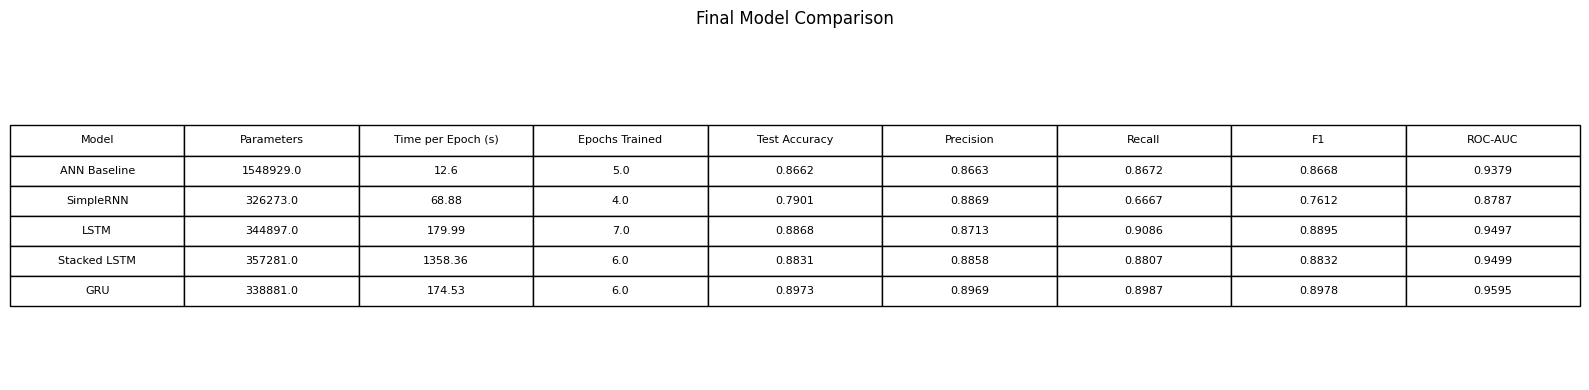

In [171]:
fig, ax = plt.subplots(
    figsize=(16, 4)
)

ax.axis("off")

table = ax.table(
    cellText=formatted_results.values,
    colLabels=formatted_results.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.7)

plt.title(
    "Final Model Comparison",
    pad=20
)

plt.tight_layout()

plt.savefig(
    "plots/results_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Best Model by Accuracy

In [172]:
best_accuracy_row = results_df.loc[
    results_df[
        "Test Accuracy"
    ].idxmax()
]

print(
    "Best Model by Test Accuracy:"
)

print(
    best_accuracy_row[
        [
            "Model",
            "Test Accuracy",
            "F1",
            "ROC-AUC",
            "Parameters"
        ]
    ]
)

Best Model by Test Accuracy:
Model                 GRU
Test Accuracy    0.897348
F1               0.897832
ROC-AUC          0.959486
Parameters       338881.0
Name: 4, dtype: object


## Best Model by F1

In [173]:
best_f1_row = results_df.loc[
    results_df["F1"].idxmax()
]

print(
    "Best Model by F1 Score:"
)

print(
    best_f1_row[
        [
            "Model",
            "Test Accuracy",
            "F1",
            "ROC-AUC",
            "Parameters"
        ]
    ]
)

Best Model by F1 Score:
Model                 GRU
Test Accuracy    0.897348
F1               0.897832
ROC-AUC          0.959486
Parameters       338881.0
Name: 4, dtype: object


# Task 7.2 — Combined ROC Curves
## Calculate ROC Values

In [174]:
ann_fpr, ann_tpr, _ = roc_curve(
    y_test,
    ann_prob
)

rnn_fpr, rnn_tpr, _ = roc_curve(
    y_test,
    rnn_prob
)

lstm_fpr, lstm_tpr, _ = roc_curve(
    y_test,
    lstm_prob
)

gru_fpr, gru_tpr, _ = roc_curve(
    y_test,
    gru_prob
)

## Plot Combined ROC

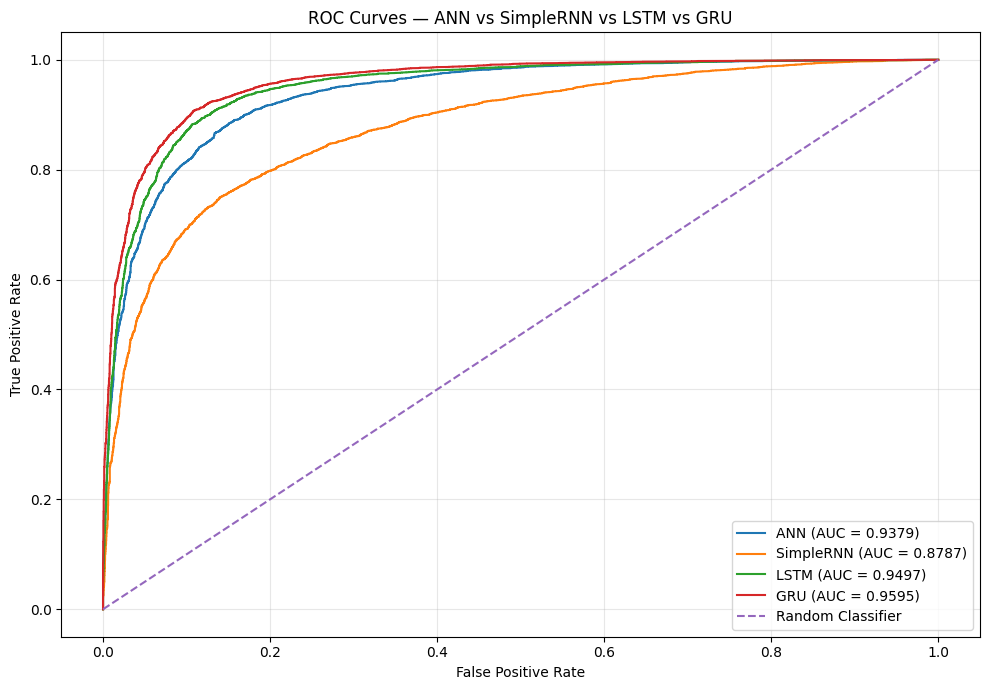

In [175]:
plt.figure(
    figsize=(10, 7)
)

plt.plot(
    ann_fpr,
    ann_tpr,
    label=f"ANN (AUC = {ann_auc:.4f})"
)

plt.plot(
    rnn_fpr,
    rnn_tpr,
    label=f"SimpleRNN (AUC = {rnn_auc:.4f})"
)

plt.plot(
    lstm_fpr,
    lstm_tpr,
    label=f"LSTM (AUC = {lstm_auc:.4f})"
)

plt.plot(
    gru_fpr,
    gru_tpr,
    label=f"GRU (AUC = {gru_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "ROC Curves — ANN vs SimpleRNN vs LSTM vs GRU"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "plots/roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### ROC Curve Interpretation

The ROC curve compares the ability of each model to separate positive
and negative movie reviews across different classification thresholds.

A curve closer to the top-left corner indicates better discrimination.

The ROC-AUC value summarizes this performance:

- AUC near `1.0` indicates strong class separation.
- AUC near `0.5` indicates performance similar to random classification.

The actual AUC values displayed in the graph should be used when deciding
which model performed best.

# Task 7.3 — Performance by Review Length
## Calculate Test Review Lengths

In [176]:
test_review_lengths = (
    X_test_text
    .apply(
        lambda text: len(
            text.split()
        )
    )
    .to_numpy()
)

print(
    "Number of Test Reviews:",
    len(test_review_lengths)
)

print(
    "Minimum Length:",
    test_review_lengths.min()
)

print(
    "Maximum Length:",
    test_review_lengths.max()
)

print(
    "Average Length:",
    test_review_lengths.mean()
)

Number of Test Reviews: 9917
Minimum Length: 8
Maximum Length: 2240
Average Length: 229.22970656448524


## Select Best Gated Model

In [177]:
if lstm_test_accuracy >= gru_test_accuracy:

    best_gated_name = "LSTM"
    best_gated_model = lstm_model
    best_gated_prob = lstm_prob
    best_gated_pred = lstm_pred

else:

    best_gated_name = "GRU"
    best_gated_model = gru_model
    best_gated_prob = gru_prob
    best_gated_pred = gru_pred


print(
    "Best Gated Model:",
    best_gated_name
)

Best Gated Model: GRU


## Create Length Groups

In [178]:
short_mask = (
    test_review_lengths < 100
)

medium_mask = (
    (test_review_lengths >= 100)
    &
    (test_review_lengths <= 250)
)

long_mask = (
    test_review_lengths > 250
)


print(
    "Short Reviews:",
    short_mask.sum()
)

print(
    "Medium Reviews:",
    medium_mask.sum()
)

print(
    "Long Reviews:",
    long_mask.sum()
)

Short Reviews: 1261
Medium Reviews: 5797
Long Reviews: 2859


## Helper Function

In [179]:
def group_accuracy(
    y_true,
    y_pred,
    mask
):

    if mask.sum() == 0:
        return np.nan

    return accuracy_score(
        y_true[mask],
        y_pred[mask]
    )

## Calculate Accuracy by Length

In [180]:
length_performance = pd.DataFrame({

    "Review Length": [
        "Short (<100)",
        "Medium (100-250)",
        "Long (>250)"
    ],

    "SimpleRNN": [

        group_accuracy(
            y_test,
            rnn_pred,
            short_mask
        ),

        group_accuracy(
            y_test,
            rnn_pred,
            medium_mask
        ),

        group_accuracy(
            y_test,
            rnn_pred,
            long_mask
        )
    ],

    best_gated_name: [

        group_accuracy(
            y_test,
            best_gated_pred,
            short_mask
        ),

        group_accuracy(
            y_test,
            best_gated_pred,
            medium_mask
        ),

        group_accuracy(
            y_test,
            best_gated_pred,
            long_mask
        )
    ]
})

length_performance

,Review Length,SimpleRNN,GRU
0,Short (<100),0.788263,0.901665
1,Medium (100-250),0.801967,0.899776
2,Long (>250),0.766702,0.890521


## Grouped Bar Chart

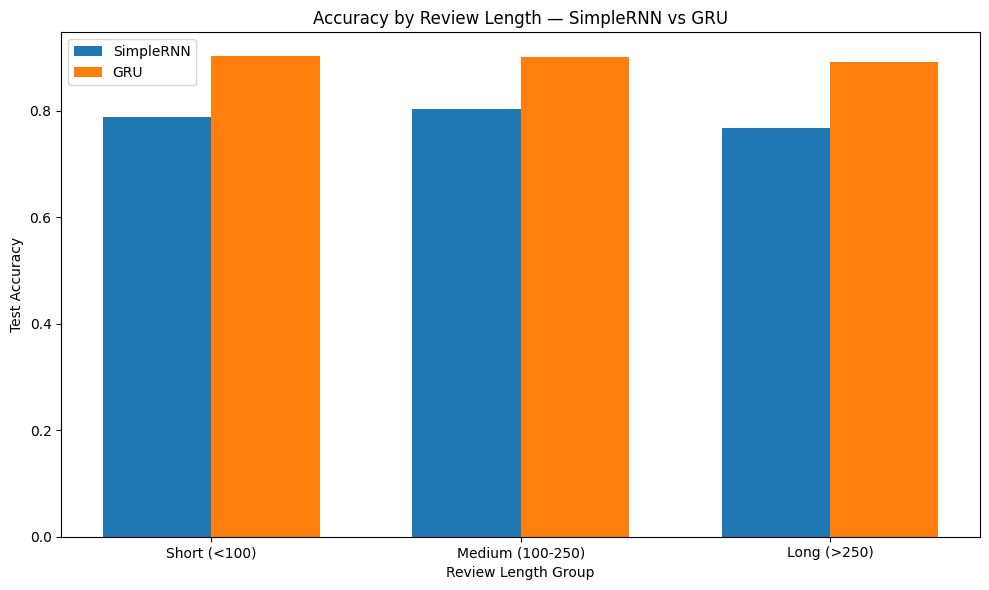

In [181]:
x = np.arange(
    len(length_performance)
)

width = 0.35

plt.figure(
    figsize=(10, 6)
)

plt.bar(
    x - width / 2,
    length_performance[
        "SimpleRNN"
    ],
    width,
    label="SimpleRNN"
)

plt.bar(
    x + width / 2,
    length_performance[
        best_gated_name
    ],
    width,
    label=best_gated_name
)

plt.xticks(
    x,
    length_performance[
        "Review Length"
    ]
)

plt.ylabel(
    "Test Accuracy"
)

plt.xlabel(
    "Review Length Group"
)

plt.title(
    f"Accuracy by Review Length — "
    f"SimpleRNN vs {best_gated_name}"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "plots/accuracy_by_length.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Review-Length Analysis

The test reviews were divided into:

- Short reviews: fewer than 100 words
- Medium reviews: 100 to 250 words
- Long reviews: more than 250 words

SimpleRNN was compared with the best-performing gated recurrent model.

The comparison helps determine whether the gated architecture provides
a greater advantage when reviews become longer.

The actual group accuracies printed above should be used to describe the
observed relationship between review length and model performance.

# Task 7.4 — Error Analysis
## Choose Overall Best Gated Model for Error Analysis

In [182]:
best_model = best_gated_model
best_model_name = best_gated_name

best_prob = best_gated_prob
best_pred = best_gated_pred

print(
    "Model Used for Error Analysis:",
    best_model_name
)

Model Used for Error Analysis: GRU


## Find False Positives and False Negatives

In [183]:
false_positive_indices = np.where(
    (y_test == 0)
    &
    (best_pred == 1)
)[0]

false_negative_indices = np.where(
    (y_test == 1)
    &
    (best_pred == 0)
)[0]

print(
    "Total False Positives:",
    len(false_positive_indices)
)

print(
    "Total False Negatives:",
    len(false_negative_indices)
)

Total False Positives: 514
Total False Negatives: 504


## Select Four of Each

In [184]:
selected_fp = (
    false_positive_indices[:4]
)

selected_fn = (
    false_negative_indices[:4]
)

print(
    "Selected FP indices:",
    selected_fp
)

print(
    "Selected FN indices:",
    selected_fn
)

Selected FP indices: [17 24 27 43]
Selected FN indices: [15 35 45 65]


## Build Misclassification Table

In [185]:
error_rows = []

for idx in selected_fp:

    error_rows.append({

        "Error Type":
            "False Positive",

        "True Label":
            "Negative",

        "Predicted Label":
            "Positive",

        "Positive Probability":
            best_prob[idx],

        "Cleaned Review":
            X_test_text.iloc[idx]
    })


for idx in selected_fn:

    error_rows.append({

        "Error Type":
            "False Negative",

        "True Label":
            "Positive",

        "Predicted Label":
            "Negative",

        "Positive Probability":
            best_prob[idx],

        "Cleaned Review":
            X_test_text.iloc[idx]
    })


error_analysis_df = pd.DataFrame(
    error_rows
)

error_analysis_df

,Error Type,True Label,Predicted Label,Positive Probability,Cleaned Review
0,False Positive,Negative,Positive,0.619519,i see this movie as a poor tribute to the old ...
1,False Positive,Negative,Positive,0.770311,despite being a huge fan of fred astaire and g...
2,False Positive,Negative,Positive,0.714605,i'm both amused and disgusted by the people wh...
3,False Positive,Negative,Positive,0.668720,ok let me again admit that i haven't seen any ...
4,False Negative,Positive,Negative,0.356048,this isn't exactly a great film but i admire t...
5,False Negative,Positive,Negative,0.135526,well well roeg touched a bit of a nerve there ...
6,False Negative,Positive,Negative,0.075262,i'm not here to tell you armored is kubrickian...
7,False Negative,Positive,Negative,0.482951,is just as good as the original very nearly ac...


## Print Each Error Clearly

In [186]:
for i, row in error_analysis_df.iterrows():

    print(
        "=" * 90
    )

    print(
        f"Example {i + 1}"
    )

    print(
        "Error Type:",
        row["Error Type"]
    )

    print(
        "True Label:",
        row["True Label"]
    )

    print(
        "Predicted Label:",
        row["Predicted Label"]
    )

    print(
        "Positive Probability:",
        round(
            row[
                "Positive Probability"
            ],
            4
        )
    )

    print(
        "\nCleaned Review:"
    )

    print(
        row["Cleaned Review"]
    )

    print()

Example 1
Error Type: False Positive
True Label: Negative
Predicted Label: Positive
Positive Probability: 0.6195

Cleaned Review:
i see this movie as a poor tribute to the old slasher movies because it really doesn't hold a candle to the 's and 's gold era of horror this is of course where personal taste comes in this movie just falls into the category of new generation of slashers in my book the cast is the typical ones years and potential models i'm personally quite tired of that image in horror movies the old movies at least had some variation in people one or more fat people and dorks in general just plain looking persons of course having a couple of good lookers is fine they always been there but when the entire cast is just a bunch of nice racks and butts it's getting silly i mean ok yeah i like to watch hot chicks but not in a horror that is supposed to reflect some ordinary people getting hunted down by for example a knife wielding maniac you expect the people being hunted to l

### Misclassification Analysis

Eight misclassified reviews were inspected:

- Four False Positives
- Four False Negatives

Possible reasons for sentiment-classification errors include:

1. **Negation** — phrases such as "not good" can change the meaning of
   otherwise positive words.

2. **Mixed sentiment** — a review may contain both praise and criticism.

3. **Sarcasm** — the literal words may not represent the intended sentiment.

4. **Long-range context** — the meaning of a sentence can depend on words
   appearing much earlier in the review.

5. **Rare or out-of-vocabulary words** — uncommon words may be mapped to
   the OOV token.

6. **Ambiguous reviews** — some reviews do not express strongly positive
   or negative sentiment.

The actual eight reviews printed above should be inspected before making
a final conclusion about the dominant source of error.

# Task 7.5 — predict_sentiment(text)
## Prediction Function

In [187]:
def predict_sentiment(text):

    # 1. Clean exactly as training data
    cleaned_text = clean_text(text)

    # 2. Convert text to integer sequence
    sequence = tokenizer.texts_to_sequences(
        [cleaned_text]
    )

    # 3. Pad using same MAXLEN
    padded_sequence = pad_sequences(
        sequence,
        maxlen=MAXLEN,
        padding="pre",
        truncating="pre"
    )

    # 4. Predict positive probability
    probability = float(
        best_model.predict(
            padded_sequence,
            verbose=0
        )[0][0]
    )

    # 5. Convert probability to label
    if probability >= 0.5:
        label = "Positive"
    else:
        label = "Negative"

    return {
        "label": label,
        "positive_probability": probability
    }

## Test Function Once

In [188]:
predict_sentiment(
    "This movie was absolutely wonderful and I loved it."
)

{'label': 'Positive', 'positive_probability': 0.9850381016731262}

## Create Six Reviews

In [189]:
custom_reviews = {

    "Clearly Positive":
        "This movie was absolutely fantastic. "
        "The acting was brilliant and I loved every moment.",

    "Clearly Negative":
        "This movie was terrible, boring and a complete waste of time.",

    "Negation":
        "The movie was not good and I would not recommend it.",

    "Double Negation":
        "I cannot say that this movie was not enjoyable.",

    "Sarcastic":
        "What a masterpiece, I especially loved wasting two hours of my life.",

    "Very Short":
        "Amazing movie."
}

## Predict All Six

In [190]:
custom_results = []

for review_type, review in custom_reviews.items():

    prediction = predict_sentiment(
        review
    )

    custom_results.append({

        "Review Type":
            review_type,

        "Review":
            review,

        "Prediction":
            prediction["label"],

        "Positive Probability":
            prediction[
                "positive_probability"
            ]
    })


custom_results_df = pd.DataFrame(
    custom_results
)

custom_results_df

,Review Type,Review,Prediction,Positive Probability
0,Clearly Positive,This movie was absolutely fantastic. The actin...,Positive,0.978661
1,Clearly Negative,"This movie was terrible, boring and a complete...",Negative,0.005346
2,Negation,The movie was not good and I would not recomme...,Negative,0.163033
3,Double Negation,I cannot say that this movie was not enjoyable.,Negative,0.254494
4,Sarcastic,"What a masterpiece, I especially loved wasting...",Negative,0.413952
5,Very Short,Amazing movie.,Positive,0.958931


## Format Probabilities

In [191]:
custom_results_display = (
    custom_results_df.copy()
)

custom_results_display[
    "Positive Probability"
] = custom_results_display[
    "Positive Probability"
].round(4)

custom_results_display

,Review Type,Review,Prediction,Positive Probability
0,Clearly Positive,This movie was absolutely fantastic. The actin...,Positive,0.9787
1,Clearly Negative,"This movie was terrible, boring and a complete...",Negative,0.0053
2,Negation,The movie was not good and I would not recomme...,Negative,0.1630
3,Double Negation,I cannot say that this movie was not enjoyable.,Negative,0.2545
4,Sarcastic,"What a masterpiece, I especially loved wasting...",Negative,0.4140
5,Very Short,Amazing movie.,Positive,0.9589


### Custom Review Analysis

Six manually written reviews were tested to investigate model behaviour
beyond ordinary test-set accuracy.

The clearly positive and clearly negative reviews test basic sentiment
recognition.

The negation example tests whether the model understands that words such
as "not" can reverse sentiment.

The double-negation example is more linguistically complex because its
meaning depends on the interaction of multiple negation terms.

The sarcastic example is particularly difficult because its literal
positive words can conflict with the intended negative meaning.

The very short review tests whether the model can make a prediction when
very little context is available.

The actual predictions and probabilities displayed above should be used
to discuss which cases the trained model handles correctly and which cases
remain difficult.

# Task 7.6 — Final Production Recommendation
## Automatically Summarize Best Models

In [192]:
best_accuracy_model = results_df.loc[
    results_df[
        "Test Accuracy"
    ].idxmax()
]

best_f1_model = results_df.loc[
    results_df[
        "F1"
    ].idxmax()
]

best_auc_model = results_df.loc[
    results_df[
        "ROC-AUC"
    ].idxmax()
]

fastest_model = results_df.loc[
    results_df[
        "Time per Epoch (s)"
    ].idxmin()
]


print(
    "Best Accuracy:",
    best_accuracy_model["Model"],
    round(
        best_accuracy_model[
            "Test Accuracy"
        ],
        4
    )
)

print(
    "Best F1:",
    best_f1_model["Model"],
    round(
        best_f1_model["F1"],
        4
    )
)

print(
    "Best ROC-AUC:",
    best_auc_model["Model"],
    round(
        best_auc_model["ROC-AUC"],
        4
    )
)

print(
    "Fastest Training:",
    fastest_model["Model"],
    round(
        fastest_model[
            "Time per Epoch (s)"
        ],
        2
    ),
    "seconds/epoch"
)

Best Accuracy: GRU 0.8973
Best F1: GRU 0.8978
Best ROC-AUC: GRU 0.9595
Fastest Training: ANN Baseline 12.6 seconds/epoch


## Gated Models Only

In [193]:
production_candidates = results_df[
    results_df["Model"].isin(
        [
            "LSTM",
            "GRU"
        ]
    )
].copy()

production_candidates

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
2,LSTM,344897.0,179.985836,7.0,0.886760,0.871291,0.908579,0.889545,0.949691
4,GRU,338881.0,174.526681,6.0,0.897348,0.896932,0.898734,0.897832,0.959486


## Dynamic Recommendation

In [194]:
best_production_row = (
    production_candidates.loc[
        production_candidates[
            "F1"
        ].idxmax()
    ]
)

recommended_model_name = (
    best_production_row["Model"]
)

print(
    "Recommended Model Based on "
    "Highest F1 Among LSTM/GRU:"
)

print(
    recommended_model_name
)

print(
    "\nAccuracy:",
    round(
        best_production_row[
            "Test Accuracy"
        ],
        4
    )
)

print(
    "F1:",
    round(
        best_production_row[
            "F1"
        ],
        4
    )
)

print(
    "ROC-AUC:",
    round(
        best_production_row[
            "ROC-AUC"
        ],
        4
    )
)

print(
    "Parameters:",
    int(
        best_production_row[
            "Parameters"
        ]
    )
)

print(
    "Time/Epoch:",
    round(
        best_production_row[
            "Time per Epoch (s)"
        ],
        2
    )
)

Recommended Model Based on Highest F1 Among LSTM/GRU:
GRU

Accuracy: 0.8973
F1: 0.8978
ROC-AUC: 0.9595
Parameters: 338881
Time/Epoch: 174.53


# Final Production Recommendation

The final model should be selected using more than test accuracy alone.

The following factors were considered:

- Test accuracy
- Precision
- Recall
- F1 score
- ROC-AUC
- Parameter count
- Training time per epoch
- Gradient behaviour
- Performance on different review lengths
- Behaviour on difficult custom reviews

SimpleRNN provides a useful recurrent baseline but has difficulty with
long-term dependencies because of vanishing gradients.

LSTM introduces a separate cell state and three gates, which improves its
ability to preserve long-range information. However, this also increases
the number of parameters and computational cost.

GRU provides gated recurrent memory using a simpler architecture with
fewer recurrent parameters than LSTM.

The final production choice should therefore be the gated model that gives
the strongest balance between predictive performance and computational
cost in the results obtained above.

The exact final recommendation and numerical justification should be based
on the executed results table rather than assumed before training.

# Task 7.7 — Final Required Training-Curve Figure
## Combined Loss Curves

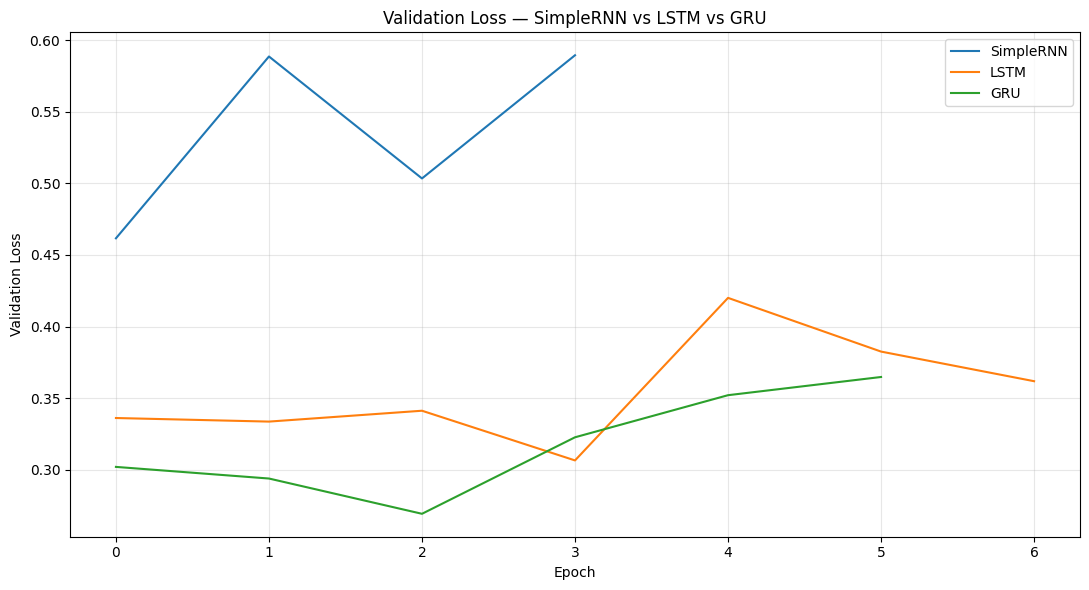

In [195]:
plt.figure(
    figsize=(11, 6)
)

plt.plot(
    rnn_history.history["val_loss"],
    label="SimpleRNN"
)

plt.plot(
    lstm_history.history["val_loss"],
    label="LSTM"
)

plt.plot(
    gru_history.history["val_loss"],
    label="GRU"
)

plt.title(
    "Validation Loss — SimpleRNN vs LSTM vs GRU"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Validation Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "plots/training_curves_rnn_lstm_gru.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Combined Accuracy Curves

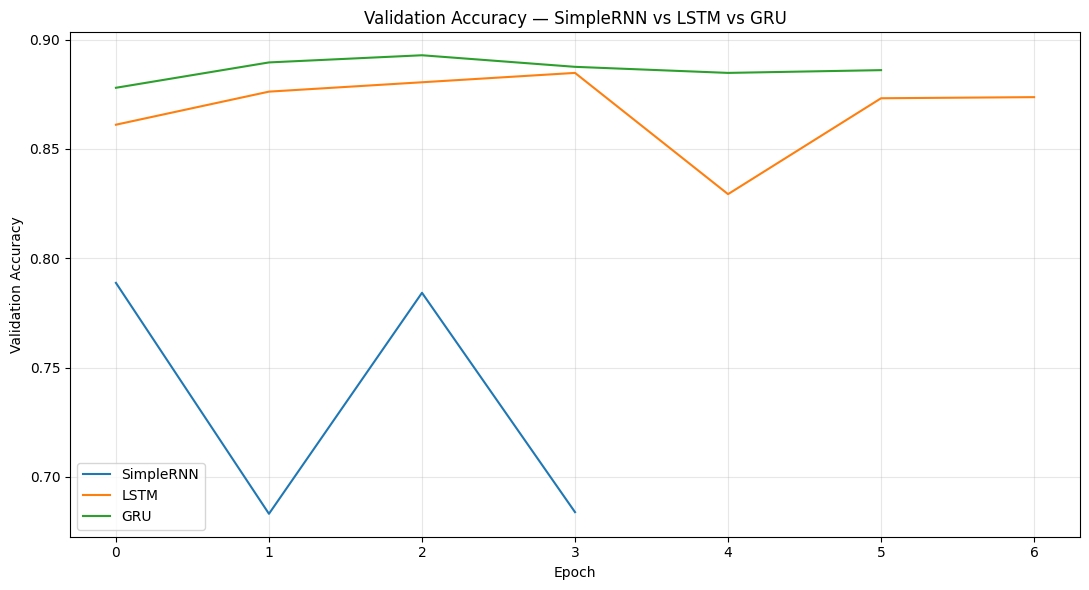

In [196]:
plt.figure(
    figsize=(11, 6)
)

plt.plot(
    rnn_history.history["val_accuracy"],
    label="SimpleRNN"
)

plt.plot(
    lstm_history.history["val_accuracy"],
    label="LSTM"
)

plt.plot(
    gru_history.history["val_accuracy"],
    label="GRU"
)

plt.title(
    "Validation Accuracy — SimpleRNN vs LSTM vs GRU"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Validation Accuracy"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

## Verify Required Plot Files

In [197]:
required_plots = [
    "length_distribution.png",
    "rnn_forward_heatmap.png",
    "gradient_norms_all_cells.png",
    "training_curves_rnn_lstm_gru.png",
    "roc_curves.png",
    "results_table.png",
    "accuracy_by_length.png"
]

print(
    "REQUIRED PLOT CHECK"
)

print(
    "=" * 60
)

for filename in required_plots:

    filepath = os.path.join(
        "plots",
        filename
    )

    if os.path.exists(filepath):

        print(
            "FOUND   :",
            filepath
        )

    else:

        print(
            "MISSING :",
            filepath
        )

REQUIRED PLOT CHECK
FOUND   : plots\length_distribution.png
FOUND   : plots\rnn_forward_heatmap.png
FOUND   : plots\gradient_norms_all_cells.png
FOUND   : plots\training_curves_rnn_lstm_gru.png
FOUND   : plots\roc_curves.png
FOUND   : plots\results_table.png
FOUND   : plots\accuracy_by_length.png


## Create requirements.txt

In [198]:
requirements = """tensorflow
scikit-learn
pandas
numpy
matplotlib
seaborn
jupyter
"""

with open(
    "requirements.txt",
    "w"
) as file:

    file.write(
        requirements
    )

print(
    "requirements.txt created successfully."
)

requirements.txt created successfully.


## Check requirements.txt

In [199]:
with open(
    "requirements.txt",
    "r"
) as file:

    print(
        file.read()
    )

tensorflow
scikit-learn
pandas
numpy
matplotlib
seaborn
jupyter



# Final Notebook Summary

# Final Conclusion

This practical implemented and compared multiple neural-network
architectures for IMDB movie-review sentiment classification.

The experiment started with a Flatten-based ANN baseline and then
progressed through three recurrent architectures:

- SimpleRNN
- LSTM
- GRU

A stacked LSTM was also evaluated.

The practical demonstrated RNN forward propagation manually using NumPy
and verified the calculation against Keras.

Backpropagation Through Time was studied to understand the vanishing and
exploding-gradient problems.

LSTM and GRU were then investigated as gated alternatives designed to
handle longer-range dependencies more effectively.

The models were compared using:

- Accuracy
- Precision
- Recall
- F1 score
- ROC-AUC
- Parameter count
- Training time
- Gradient behaviour
- Review-length performance
- Error analysis
- Custom sentiment examples

The final production model should be selected from the actual experimental
results, balancing predictive performance with computational complexity.

## Final Project Check

In [200]:
print(
    "=" * 70
)

print(
    "DL PR5 FINAL PROJECT CHECK"
)

print(
    "=" * 70
)

print(
    "Dataset Shape:",
    df.shape
)

print(
    "Training Samples:",
    len(X_train)
)

print(
    "Testing Samples:",
    len(X_test)
)

print(
    "Vocabulary Size:",
    VOCAB_SIZE
)

print(
    "MAXLEN:",
    MAXLEN
)

print(
    "\nModels Completed:"
)

for model_name in results.keys():

    print(
        "✓",
        model_name
    )

print(
    "\nTotal Models:",
    len(results)
)

print(
    "\nRequired Models = 5"
)

print(
    "\nFinal Results:"
)

display(
    formatted_results
)

DL PR5 FINAL PROJECT CHECK
Dataset Shape: (49582, 5)
Training Samples: 39665
Testing Samples: 9917
Vocabulary Size: 10000
MAXLEN: 600

Models Completed:
✓ ANN Baseline
✓ SimpleRNN
✓ LSTM
✓ Stacked LSTM
✓ GRU

Total Models: 5

Required Models = 5

Final Results:


,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN Baseline,1548929.0,12.60,5.0,0.8662,0.8663,0.8672,0.8668,0.9379
1,SimpleRNN,326273.0,68.88,4.0,0.7901,0.8869,0.6667,0.7612,0.8787
2,LSTM,344897.0,179.99,7.0,0.8868,0.8713,0.9086,0.8895,0.9497
3,Stacked LSTM,357281.0,1358.36,6.0,0.8831,0.8858,0.8807,0.8832,0.9499
4,GRU,338881.0,174.53,6.0,0.8973,0.8969,0.8987,0.8978,0.9595
